# 05 — Pattern Discovery & Validation

**Goal:** Map clusters to failure events and subsystems, consolidate into high-level patterns, compare heuristic approaches, validate each cluster (keep/junk), and build full traceability from raw sensors to failures.

**Depends on:** NB04 (cluster assignments, activation matrix, statistical analysis)

In [ ]:
import sys, os, gc, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from matplotlib.gridspec import GridSpec

OUT = os.path.join("..", "outputs")
os.makedirs(OUT, exist_ok=True)

# Load windowed datasets
train_sup = pd.read_parquet(os.path.join(OUT, "supervised", "train.parquet"))
test_sup = pd.read_parquet(os.path.join(OUT, "supervised", "test.parquet"))
train_sup["window_end"] = pd.to_datetime(train_sup["window_end"])
test_sup["window_end"] = pd.to_datetime(test_sup["window_end"])

all_sup = pd.concat([train_sup, test_sup], ignore_index=True).sort_values("window_end").reset_index(drop=True)
feature_cols = [c for c in train_sup.columns if c not in ["label", "window_end", "timestamp"]]
print(f"Loaded {len(all_sup)} windows, {len(feature_cols)} features")
print(f"Train: {len(train_sup)}, Test: {len(test_sup)}")

In [ ]:
# ── Rebuild anomaly detection & clustering (reproducing NB04 results) ──
# Z-scores relative to train-normal
train_normal = all_sup.iloc[:len(train_sup)]
train_normal = train_normal[train_normal["label"] == 0]
t_mean = train_normal[feature_cols].mean()
t_std = train_normal[feature_cols].std().replace(0, 1)
z_scores = (all_sup[feature_cols] - t_mean) / t_std

# Anomalous windows: |z| > 3 in at least 5 features
anom_mask_feat = z_scores.abs() > 3
all_sup["n_anomalous_feats"] = anom_mask_feat.sum(axis=1)
all_sup["is_anomalous"] = all_sup["n_anomalous_feats"] >= 5
print(f"Anomalous windows: {all_sup["is_anomalous"].sum()} / {len(all_sup)} ({100*all_sup["is_anomalous"].mean():.1f}%)")

# Activation profiles
anom_idx = all_sup.index[all_sup["is_anomalous"]]
anom_activations = anom_mask_feat.loc[anom_idx].astype(int)

# Feature frequency filter
feat_freq = anom_activations.sum()
min_freq = max(int(len(anom_activations) * 0.01), 2)
active_feats = feat_freq[feat_freq >= min_freq].index.tolist()
print(f"Active features (>= {min_freq} windows): {len(active_feats)}")

# Hierarchical clustering
act_matrix = anom_activations[active_feats].values
dist = pdist(act_matrix.T, metric="jaccard")
Z = linkage(dist, method="average")
cluster_labels = fcluster(Z, t=0.7, criterion="distance")

# Build cluster dict and metadata
clusters = {}
for f, cl in zip(active_feats, cluster_labels):
    clusters.setdefault(int(cl), []).append(f)
valid_clusters = sorted(clusters.keys())

# Build anom_meta
anom_meta = all_sup.loc[anom_idx].copy()
anom_meta["cluster_clean"] = -1
for cl_id, feats in clusters.items():
    mask = anom_activations[feats].any(axis=1)
    anom_meta.loc[anom_idx[mask], "cluster_clean"] = cl_id

print(f"Clusters: {len(valid_clusters)}, Anomalous windows assigned: {(anom_meta["cluster_clean"] > 0).sum()}")

## 1. Link Clusters to Failure Events

For each cluster, find which failure events its windows are temporally close to. This reveals whether a cluster is a precursor to specific failure types.

In [8]:
import glob

# Load failure events from raw data
TS_COL = 'TIMESTAMP'
FAIL_COL = 'TRAIN_IS_IN_FAILURE'
FAIL_TYPE = 'TRAIN_FAILURE_TYPE'
MAINT_COL = 'TRAIN_IS_IN_MAINTENANCE'
HORIZON_S = 22326

all_files = sorted(
    glob.glob(os.path.join(ROOT, 'train', '**', '*.parquet'), recursive=True) +
    glob.glob(os.path.join(ROOT, 'test', '**', '*.parquet'), recursive=True)
)
chunks = []
for f in all_files:
    df = pd.read_parquet(f, columns=[TS_COL, FAIL_COL, FAIL_TYPE])
    chunks.append(df)
raw_meta = pd.concat(chunks, ignore_index=True)
del chunks; gc.collect()
raw_meta[TS_COL] = pd.to_datetime(raw_meta[TS_COL])
raw_meta.sort_values(TS_COL, inplace=True)

mask = raw_meta[FAIL_COL].astype(bool)
grp = (mask != mask.shift()).cumsum()
fail_events = (
    raw_meta[mask].groupby(grp[mask])
    .agg(start=(TS_COL, 'min'), end=(TS_COL, 'max'),
         event_type=(FAIL_TYPE, 'first'), n_rows=(TS_COL, 'count'))
    .reset_index(drop=True)
)
# Merge nearby events
merged = []
for _, row in fail_events.iterrows():
    if merged and row['event_type'] == merged[-1]['event_type'] and \
       (row['start'] - merged[-1]['end']).total_seconds() < 3600:
        merged[-1]['end'] = row['end']
        merged[-1]['n_rows'] += row['n_rows']
    else:
        merged.append(dict(row))
fail_events = pd.DataFrame(merged)
fail_events['duration_min'] = (fail_events['end'] - fail_events['start']).dt.total_seconds() / 60
fail_events['period'] = fail_events['start'].apply(lambda x: 'train' if x < SPLIT_DATE else 'test')
fail_events.index += 1
fail_events.index.name = 'event_id'
del raw_meta; gc.collect()

print(f'Failure events: {len(fail_events)}')

# For each anomalous window, find the nearest failure event
def find_nearest_failure(window_end, fail_events, horizon_s):
    """Find the nearest failure event within the prediction horizon."""
    horizon_end = window_end + pd.Timedelta(seconds=horizon_s)
    for idx, ev in fail_events.iterrows():
        # Window is a precursor if failure starts within horizon
        if ev['start'] >= window_end and ev['start'] <= horizon_end:
            return idx, ev['event_type'], 'precursor'
        # Window is during failure
        if ev['start'] <= window_end and ev['end'] >= window_end:
            return idx, ev['event_type'], 'during'
    return None, None, 'none'

# Map each anomalous window to failure events
print('Mapping anomalous windows to failure events...')
anom_meta['fail_event_id'] = None
anom_meta['fail_event_type'] = None
anom_meta['fail_relation'] = 'none'

for i, row in anom_meta.iterrows():
    eid, etype, rel = find_nearest_failure(row['window_end'], fail_events, HORIZON_S)
    anom_meta.at[i, 'fail_event_id'] = eid
    anom_meta.at[i, 'fail_event_type'] = etype
    anom_meta.at[i, 'fail_relation'] = rel

print(f'\nAnomalous window â€” failure relation:')
print(anom_meta['fail_relation'].value_counts().to_string())

Failure events: 21
Mapping anomalous windows to failure events...



Anomalous window â€” failure relation:
fail_relation
none         12371
during         410
precursor      344


In [9]:
# â”€â”€ Cluster Ã— Failure Event cross-tabulation â”€â”€
print('Cluster to Failure Event Mapping:')
print('='*100)

for cl in sorted(valid_clusters):
    cl_data = anom_meta[anom_meta['cluster_clean'] == cl]
    cp = cluster_profiles[cl]
    
    print(f'\n--- Cluster {cl} ({cp["size"]} windows, {cp["fail_pct"]:.1f}% failure, dominant: {cp["top_subsystem"]}) ---')
    
    # Relation breakdown
    rel_counts = cl_data['fail_relation'].value_counts()
    for rel, count in rel_counts.items():
        print(f'  {rel}: {count} windows')
    
    # Which failure types?
    linked = cl_data[cl_data['fail_relation'] != 'none']
    if len(linked) > 0:
        type_counts = linked['fail_event_type'].value_counts()
        for ft, count in type_counts.items():
            event_ids = linked.loc[linked['fail_event_type'] == ft, 'fail_event_id'].unique()
            print(f'  â†’ {ft}: {count} windows across events {sorted([int(e) for e in event_ids if e is not None])}')
    
    # Top 5 activated features in this cluster
    profile = cp['profile']
    top5 = profile.nlargest(5)
    print(f'  Top features: ', end='')
    print(', '.join([f'{f.split("_")[-1]}({feat_subsystem[f][0]})' if len(f) > 30 
                     else f'{f}({feat_subsystem[f][0]})' for f, v in top5.items()]))

Cluster to Failure Event Mapping:

--- Cluster 1 (13 windows, 0.0% failure, dominant: Brake) ---
  none: 13 windows
  Top features: MW4_LOAD_SIGNAL_min(L), max(B), max(T), mean(T), max(B)

--- Cluster 7 (5 windows, 20.0% failure, dominant: Brake) ---
  none: 4 windows
  precursor: 1 windows
  â†’ Brake System Failure: 1 windows across events [14]
  Top features: min(B), sum(B), sum(B), sum(B), min(B)

--- Cluster 8 (2405 windows, 3.5% failure, dominant: Brake) ---
  none: 2320 windows
  during: 47 windows
  precursor: 38 windows
  â†’ Brake System Failure: 61 windows across events [1, 4, 6, 7, 9, 10, 13, 14, 15, 20]
  â†’ Compressor Module Failure: 18 windows across events [12, 17, 19, 21]
  â†’ Leveling System Failure: 6 windows across events [18]
  Top features: min(B), min(B), min(B), min(B), min(B)

--- Cluster 9 (12 windows, 8.3% failure, dominant: Leveling) ---
  none: 11 windows
  during: 1 windows
  â†’ Brake System Failure: 1 windows across events [6]
  Top features: CW1_LOAD_

## 2. Map Clusters to Subsystems

Visualize how each cluster's activated features map to subsystems. This reveals whether clusters align with domain subsystems or span across them.

In [ ]:
# Subsystem activation breakdown per cluster — improved 3-panel layout
subsystems = ['Brake', 'Leveling', 'APU']
sub_colors = {'Brake': '#e74c3c', 'Leveling': '#2ecc71', 'APU': '#3498db', 'Other': '#95a5a6'}

# Build per-cluster subsystem composition
cl_ids_sorted = sorted(clusters.keys())
rows = []
for cl_id in cl_ids_sorted:
    feats = clusters[cl_id]
    sub_counts = {s: 0 for s in subsystems}
    sub_counts['Other'] = 0
    for f in feats:
        matched = False
        for s in subsystems:
            if s.lower() in f.lower():
                sub_counts[s] += 1
                matched = True
                break
        if not matched:
            sub_counts['Other'] += 1

    total = max(sum(sub_counts.values()), 1)
    cl_windows = act[feats].any(axis=1)
    n_win = cl_windows.sum()
    n_fail = int(all_sup.loc[anom_idx[cl_windows], 'label'].sum()) if n_win > 0 else 0
    fail_pct = 100 * n_fail / max(n_win, 1)

    rows.append({
        'cluster': cl_id,
        'n_feats': len(feats),
        **{s: sub_counts[s] / total for s in subsystems},
        'Other': sub_counts['Other'] / total,
        'n_windows': n_win,
        'fail_pct': fail_pct,
    })

df_cl = pd.DataFrame(rows)
# Sort by dominant subsystem then failure rate
df_cl['dominant'] = df_cl[subsystems + ['Other']].idxmax(axis=1)
df_cl = df_cl.sort_values(['dominant', 'fail_pct'], ascending=[True, False]).reset_index(drop=True)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, max(8, len(df_cl) * 0.28)),
                                     gridspec_kw={'width_ratios': [3, 1.2, 1.2]})

y_pos = np.arange(len(df_cl))
labels = [f"C{r['cluster']} ({r['n_feats']}f)" for _, r in df_cl.iterrows()]

# LEFT: Stacked horizontal bar — subsystem composition
left = np.zeros(len(df_cl))
for sub in subsystems + ['Other']:
    vals = df_cl[sub].values
    ax1.barh(y_pos, vals, left=left, color=sub_colors[sub], label=sub, edgecolor='white', linewidth=0.5)
    left += vals

ax1.set_yticks(y_pos)
ax1.set_yticklabels(labels, fontsize=7)
ax1.set_xlabel('Subsystem Composition (%)')
ax1.set_title('Subsystem Composition per Cluster', fontweight='bold')
ax1.legend(loc='lower right', fontsize=8)
ax1.set_xlim(0, 1)
ax1.invert_yaxis()

# MIDDLE: Failure rate bars
colors_fail = ['#e74c3c' if v >= 10 else '#f39c12' if v >= 5 else '#27ae60' for v in df_cl['fail_pct']]
ax2.barh(y_pos, df_cl['fail_pct'], color=colors_fail, edgecolor='white', linewidth=0.5)
ax2.set_xlabel('Failure Rate (%)')
ax2.set_title('Failure %', fontweight='bold')
ax2.set_yticks([])
ax2.invert_yaxis()
ax2.axvline(x=10, color='red', linestyle='--', alpha=0.5, linewidth=0.8)

# RIGHT: Window count bars
ax3.barh(y_pos, df_cl['n_windows'], color='#34495e', edgecolor='white', linewidth=0.5, alpha=0.7)
ax3.set_xlabel('Window Count')
ax3.set_title('# Windows', fontweight='bold')
ax3.set_yticks([])
ax3.invert_yaxis()

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'subsystem_activation_breakdown.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"Clusters: {len(df_cl)} | High-failure (≥10%): {(df_cl['fail_pct']>=10).sum()} | Large (≥500 windows): {(df_cl['n_windows']>=500).sum()}")



In [11]:
# â”€â”€ Cluster activation profile comparison (heatmap) â”€â”€
# Show which features define each cluster
profile_matrix = pd.DataFrame({f'C{cl}': cluster_profiles[cl]['profile'] for cl in sorted(valid_clusters)})

# Keep only features activated in > 20% of windows in at least one cluster
significant = profile_matrix.max(axis=1) > 0.2
profile_sig = profile_matrix[significant].copy()

# Sort by subsystem
profile_sig['subsystem'] = [feat_subsystem[f] for f in profile_sig.index]
sub_order = ['Brake', 'Leveling', 'APU', 'Traction', 'Context', 'Asset']
profile_sig['sub_rank'] = profile_sig['subsystem'].map({s: i for i, s in enumerate(sub_order)})
profile_sig = profile_sig.sort_values(['sub_rank', profile_sig.columns[0]], ascending=[True, False])
subsystem_labels = profile_sig['subsystem'].values
profile_sig = profile_sig.drop(columns=['subsystem', 'sub_rank'])

fig, ax = plt.subplots(figsize=(max(8, n_cl * 2), max(10, len(profile_sig) * 0.25)))
im = ax.imshow(profile_sig.values, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(profile_sig.columns)))
ax.set_xticklabels(profile_sig.columns, fontsize=10)
ax.set_yticks(range(len(profile_sig)))
short_names = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
               .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
               .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
               .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
               for f in profile_sig.index]
ax.set_yticklabels(short_names, fontsize=6)

# Color y-labels by subsystem
for i, sub in enumerate(subsystem_labels):
    ax.get_yticklabels()[i].set_color(sub_colors.get(sub, 'black'))

plt.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label='Activation frequency')
ax.set_title('Cluster Activation Profiles â€” Features Activated in >20% of Cluster Windows', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Construct Subsystem-Aware Feature Groups

Based on the cluster analysis, define feature groups that can be used as subsystem-aware subdatasets.

Each group contains the sensors that co-activate during a specific anomaly pattern.

In [12]:
# For each cluster, identify the core features (activated in >30% of windows)
CORE_THRESHOLD = 0.30

feature_groups = {}
skipped_clusters = []
print('Subsystem-Aware Feature Groups (from anomaly clusters):')
print('='*90)

for cl in sorted(valid_clusters):
    cp = cluster_profiles[cl]
    profile = cp['profile']
    core_feats = profile[profile >= CORE_THRESHOLD].sort_values(ascending=False)
    
    # Map core features back to raw sensor names
    core_sensors = set()
    for f in core_feats.index:
        for suffix in ['_min', '_max', '_mean', '_sum', '_active_s', '_flips']:
            if f.endswith(suffix):
                core_sensors.add(f[:-len(suffix)])
                break
    
    if not core_sensors:
        skipped_clusters.append(cl)
        print(f'\n  Cluster {cl}: SKIPPED â€” no features above {CORE_THRESHOLD:.0%} threshold')
        continue
    
    # All features derived from these sensors
    group_features = [f for f in feature_cols if any(f.startswith(s) for s in core_sensors)]
    
    # Subsystem composition
    sensor_subs = {}
    for s in core_sensors:
        sub = get_subsystem(s + '_mean')
        sensor_subs.setdefault(sub, []).append(s)
    
    if not sensor_subs:
        skipped_clusters.append(cl)
        print(f'\n  Cluster {cl}: SKIPPED â€” no subsystem mapping')
        continue
    
    # Name the group based on composition
    dominant = max(sensor_subs, key=lambda k: len(sensor_subs[k]))
    if len(sensor_subs) == 1:
        group_name = f'C{cl}_{dominant}'
    else:
        group_name = f'C{cl}_Cross({"_".join(sorted(sensor_subs.keys()))})'
    
    feature_groups[group_name] = {
        'cluster_id': cl,
        'sensors': sorted(core_sensors),
        'features': sorted(group_features),
        'n_sensors': len(core_sensors),
        'n_features': len(group_features),
        'subsystem_composition': {k: sorted(v) for k, v in sensor_subs.items()},
        'cluster_size': cp['size'],
        'failure_pct': cp['fail_pct'],
        'linked_failure_types': list(anom_meta.loc[
            (anom_meta['cluster_clean'] == cl) & (anom_meta['fail_relation'] != 'none'),
            'fail_event_type'
        ].dropna().unique()),
    }
    
    print(f'\n{group_name}:')
    print(f'  From cluster {cl}: {cp["size"]} windows, {cp["fail_pct"]:.1f}% failure')
    print(f'  Sensors: {len(core_sensors)} â†’ Features: {len(group_features)}')
    print(f'  Subsystem composition:')
    for sub, sensors in sorted(sensor_subs.items()):
        print(f'    {sub}: {len(sensors)} sensors â€” {sensors[:5]}{"..." if len(sensors)>5 else ""}')
    if feature_groups[group_name]['linked_failure_types']:
        print(f'  Linked failure types: {feature_groups[group_name]["linked_failure_types"]}')
    else:
        print(f'  Linked failure types: NONE (operational anomaly only)')

print(f'\n{"="*90}')
print(f'Total feature groups: {len(feature_groups)}')
if skipped_clusters:
    print(f'Skipped clusters (no core features): {skipped_clusters}')

Subsystem-Aware Feature Groups (from anomaly clusters):

  Cluster 1: SKIPPED â€” no features above 30% threshold

C7_Brake:
  From cluster 7: 5 windows, 20.0% failure
  Sensors: 5 â†’ Features: 20
  Subsystem composition:
    Brake: 5 sensors â€” ['CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1', 'MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1', 'MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1', 'CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2', 'CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1']
  Linked failure types: ['Brake System Failure']

C8_Cross(Brake_Leveling):
  From cluster 8: 2405 windows, 3.5% failure
  Sensors: 13 â†’ Features: 52
  Subsystem composition:
    Brake: 12 sensors â€” ['CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1', 'MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1', 'MW1_BRAKE_CYLINDER_PRESSURE_BOGIE2', 'MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1', 'MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1']...
    Leveling: 1 sensors â€” ['MW4_LOAD_SIGNAL']
  Linked failure types: ['Brake System Failure', 'Compressor Module Failure', 'Leveling System Failure']

C9_Cross(A

In [13]:
# â”€â”€ Save feature groups for expert verification â”€â”€
# Clean for JSON serialization
groups_for_json = {}
for name, info in feature_groups.items():
    groups_for_json[name] = {
        'cluster_id': int(info['cluster_id']),
        'sensors': info['sensors'],
        'n_sensors': info['n_sensors'],
        'features': info['features'],
        'n_features': info['n_features'],
        'subsystem_composition': info['subsystem_composition'],
        'cluster_size': int(info['cluster_size']),
        'failure_pct': round(info['failure_pct'], 1),
        'linked_failure_types': info['linked_failure_types'],
    }

out_path = os.path.join(OUT_DIR, 'feature_groups.json')
with open(out_path, 'w') as f:
    json.dump(groups_for_json, f, indent=2)
print(f'Saved feature groups to {out_path}')

Saved feature groups to C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\feature_groups.json


## 4. Summary for Expert Verification

Summary table and chain diagram for the meeting with domain experts.

In [14]:
# â”€â”€ Meeting-ready summary â”€â”€
print('='*90)
print('ANOMALY PATTERN DISCOVERY â€” SUMMARY FOR EXPERT VERIFICATION')
print('='*90)

print(f'\nDataset: {len(all_sup):,} windows (Jun 2024 â€“ Jun 2025)')
print(f'Anomalous windows (|z|>{Z_THRESH}, >={MIN_ACTIVATED} features): {n_anom}')
print(f'Clustering: Jaccard distance + average linkage, cut={CUT_THRESHOLD}')
print(f'Valid clusters (>=5 windows): {len(valid_clusters)}')

print(f'\n--- Feature â†’ Event â†’ Failure â†’ Dataset Chain ---')
print(f'')
for name, info in feature_groups.items():
    fail_types = info['linked_failure_types']
    fail_str = ', '.join(fail_types) if fail_types else 'None (operational)'
    subs = list(info['subsystem_composition'].keys())
    print(f'  {name}:')
    print(f'    Features:  {info["n_sensors"]} sensors â†’ {info["n_features"]} features')
    print(f'    Subsystems: {subs}')
    print(f'    Events:    {info["cluster_size"]} anomalous windows ({info["failure_pct"]:.0f}% with failure label)')
    print(f'    Failures:  {fail_str}')
    print(f'    â†’ Dataset: {info["n_features"]} features from {subs}')
    print()

print('--- Baseline Comparison ---')
print(f'  FULL Baseline: {len(feature_cols)} features (all sensors, flat)')
for name, info in feature_groups.items():
    print(f'  {name}: {info["n_features"]} features ({info["n_sensors"]} sensors)')

print(f'\n--- Questions for Domain Experts ---')
print('  1. Do these sensor groupings make operational sense?')
print('  2. Are there known failure modes that align with these patterns?')
print('  3. Should any clusters be merged or split?')
print('  4. Are the "operational-only" clusters (no failure link) expected behavior?')

ANOMALY PATTERN DISCOVERY â€” SUMMARY FOR EXPERT VERIFICATION

Dataset: 64,522 windows (Jun 2024 â€“ Jun 2025)
Anomalous windows (|z|>3.0, >=5 features): 13125
Clustering: Jaccard distance + average linkage, cut=0.75
Valid clusters (>=5 windows): 54

--- Feature â†’ Event â†’ Failure â†’ Dataset Chain ---

  C7_Brake:
    Features:  5 sensors â†’ 20 features
    Subsystems: ['Brake']
    Events:    5 anomalous windows (20% with failure label)
    Failures:  Brake System Failure
    â†’ Dataset: 20 features from ['Brake']

  C8_Cross(Brake_Leveling):
    Features:  13 sensors â†’ 52 features
    Subsystems: ['Brake', 'Leveling']
    Events:    2405 anomalous windows (4% with failure label)
    Failures:  Brake System Failure, Compressor Module Failure, Leveling System Failure
    â†’ Dataset: 52 features from ['Brake', 'Leveling']

  C9_Cross(APU_Leveling):
    Features:  5 sensors â†’ 16 features
    Subsystems: ['Leveling', 'APU']
    Events:    12 anomalous windows (8% with failure l

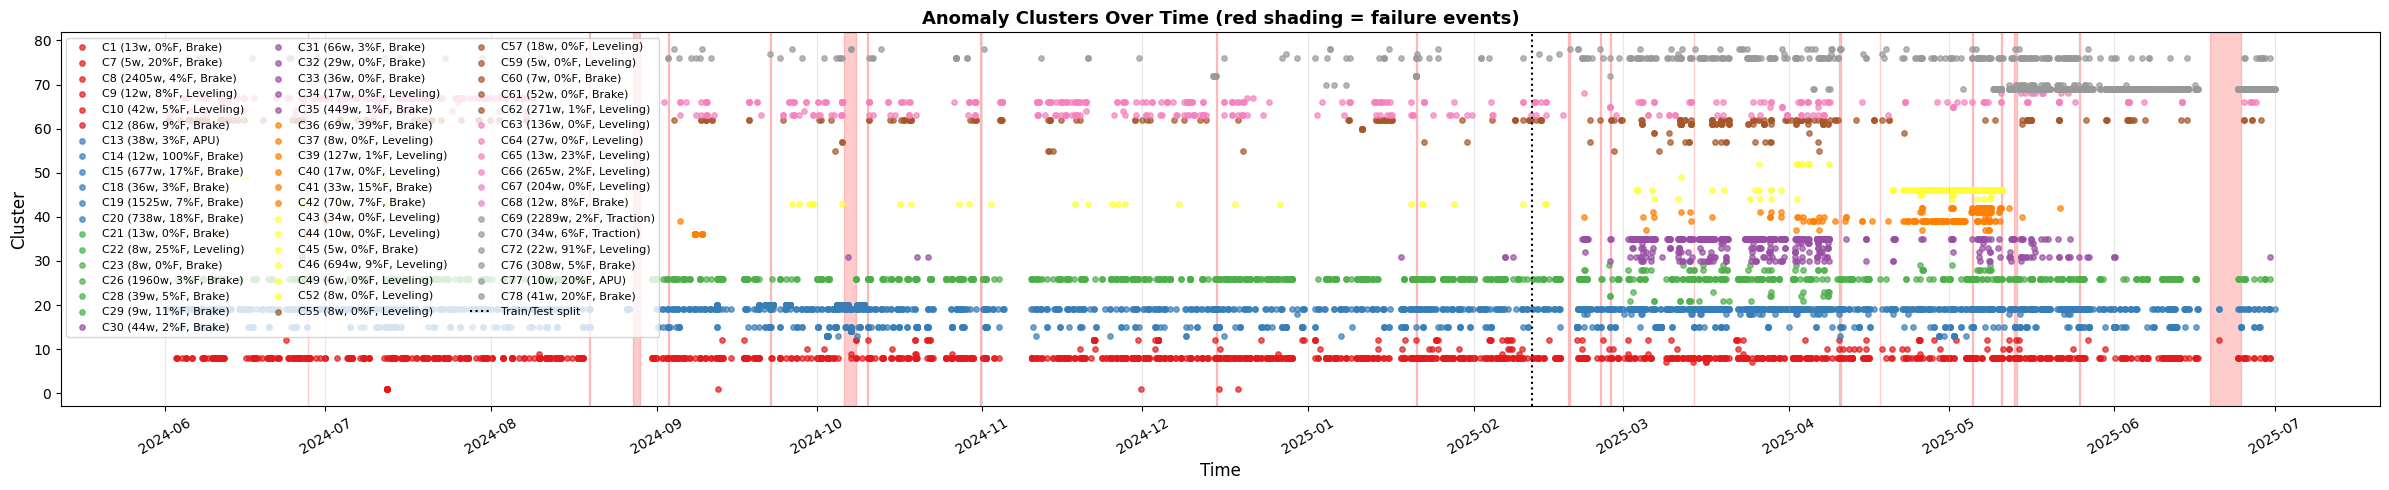

Saved anomaly_clusters_timeline.png


In [15]:
# â”€â”€ Timeline: show where each cluster's windows appear â”€â”€
fig, ax = plt.subplots(figsize=(24, 5))

cluster_colors = plt.cm.Set1(np.linspace(0, 1, max(len(valid_clusters), 3)))
cl_color_map = {cl: cluster_colors[i] for i, cl in enumerate(sorted(valid_clusters))}

# Plot failure events
for _, ev in fail_events.iterrows():
    ax.axvspan(ev['start'], ev['end'], alpha=0.2, color='red')

# Plot cluster windows
for cl in sorted(valid_clusters):
    cl_data = anom_meta[anom_meta['cluster_clean'] == cl]
    ax.scatter(cl_data['window_end'], [cl] * len(cl_data),
              s=15, c=[cl_color_map[cl]], alpha=0.7,
              label=f'C{cl} ({cluster_profiles[cl]["size"]}w, {cluster_profiles[cl]["fail_pct"]:.0f}%F, {cluster_profiles[cl]["top_subsystem"]})')

ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1.5, label='Train/Test split')
ax.set_xlabel('Time', fontsize=12)
ax.set_ylabel('Cluster', fontsize=12)
ax.set_title('Anomaly Clusters Over Time (red shading = failure events)', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=8, ncol=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=30)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'anomaly_clusters_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved anomaly_clusters_timeline.png')

## 5. Consolidated Anomaly Patterns

The 54 fine-grained clusters are too many to present. We consolidate them into **6 high-level anomaly patterns** based on:
- Which subsystem dominates
- Which brake sensor types are involved (cylinder pressure vs spring brake vs proportional valve)
- Sensor overlap between clusters

| Pattern | Description | Key Subsystems |
|---------|-------------|----------------|
| P1 | Brake cylinder & proportional valve pressure | Brake + Leveling |
| P2 | Spring brake pressure & braking force (high failure%) | Brake + Leveling |
| P3 | Full multi-subsystem (includes 100% failure cluster) | APU + Brake + Leveling + Traction |
| P4 | Load pressure & load signal | Leveling only |
| P5 | Energy braking resistance | Traction only |
| P6 | Compressor & main reservoir pressure | APU-centered |

In [16]:
# ── Consolidate 54 clusters into 6 high-level patterns ──

def merge_clusters(cluster_names, groups_dict):
    """Merge multiple fine-grained clusters into one consolidated pattern."""
    members = [groups_dict[n] for n in cluster_names if n in groups_dict]
    if not members:
        return None
    
    all_sensors = sorted(set(s for m in members for s in m['sensors']))
    all_features = sorted(set(f for m in members for f in m['features']))
    all_failure_types = sorted(set(ft for m in members for ft in m['linked_failure_types']))
    
    sub_comp = {}
    for m in members:
        for sub, sensors in m['subsystem_composition'].items():
            sub_comp.setdefault(sub, set()).update(sensors)
    sub_comp = {k: sorted(v) for k, v in sub_comp.items()}
    
    total_windows = sum(m['cluster_size'] for m in members)
    total_fail = sum(m['cluster_size'] * m['failure_pct'] / 100 for m in members)
    fail_pct = (total_fail / total_windows * 100) if total_windows > 0 else 0
    
    cluster_ids = [m['cluster_id'] for m in members]
    
    return {
        'merged_from': cluster_names,
        'n_merged': len(members),
        'cluster_ids': cluster_ids,
        'sensors': all_sensors,
        'features': all_features,
        'n_sensors': len(all_sensors),
        'n_features': len(all_features),
        'subsystem_composition': sub_comp,
        'total_windows': total_windows,
        'failure_pct': round(fail_pct, 1),
        'linked_failure_types': all_failure_types,
    }

# Define the 6 consolidated patterns
pattern_defs = {
    'P1_BrakeCylinder': {
        'desc': 'Brake cylinder & proportional valve pressure anomalies with load signal deviations',
        'clusters': [
            'C8_Cross(Brake_Leveling)', 'C26_Cross(Brake_Leveling)',
            'C28_Cross(Brake_Leveling)', 'C42_Cross(Brake_Leveling)',
            'C61_Cross(Brake_Leveling)', 'C37_Cross(Brake_Leveling)',
            'C52_Cross(Brake_Leveling)', 'C40_Cross(Brake_Leveling)',
            'C59_Cross(Brake_Leveling)',
            'C7_Brake', 'C35_Brake', 'C30_Brake', 'C32_Brake', 'C33_Brake',
        ],
    },
    'P2_SpringBrake': {
        'desc': 'Spring brake pressure & braking force anomalies — high failure linkage',
        'clusters': [
            'C15_Cross(Brake_Leveling)', 'C72_Cross(Brake_Leveling)',
            'C20_Cross(Brake_Leveling)', 'C36_Cross(Brake_Leveling)',
            'C60_Cross(Brake_Leveling)',
            'C41_Cross(Brake_Leveling)', 'C29_Cross(Brake_Leveling)',
            'C21_Cross(Brake_Leveling)', 'C23_Cross(Brake_Leveling)',
            'C34_Cross(Brake_Leveling)',
        ],
    },
    'P3_FullSystem': {
        'desc': 'Multi-subsystem anomalies (APU + Brake + Leveling + Traction) — includes highest-purity failure clusters',
        'clusters': [
            'C19_Cross(APU_Brake_Leveling_Traction)',
            'C12_Cross(APU_Brake_Leveling)', 'C14_Cross(APU_Brake_Leveling)',
            'C13_Cross(APU_Brake_Leveling)', 'C22_Cross(APU_Brake_Leveling)',
            'C45_Cross(APU_Brake_Leveling)',
            'C78_Cross(Brake_Leveling_Traction)',
            'C18_Cross(APU_Brake_Traction)',
            'C31_Cross(Brake_Traction)', 'C68_Cross(Brake_Traction)',
        ],
    },
    'P4_Leveling': {
        'desc': 'Load pressure and load signal anomalies in the leveling subsystem',
        'clusters': [
            'C46_Leveling', 'C62_Leveling', 'C66_Leveling', 'C67_Leveling',
            'C63_Leveling', 'C39_Leveling', 'C43_Leveling', 'C64_Leveling',
            'C57_Leveling', 'C65_Leveling', 'C44_Leveling', 'C55_Leveling',
            'C49_Leveling',
        ],
    },
    'P5_Traction': {
        'desc': 'Energy braking resistance anomalies — large cluster, test-period dominant',
        'clusters': ['C69_Traction'],
    },
    'P6_APU': {
        'desc': 'Compressor and main reservoir pressure anomalies — APU-centered',
        'clusters': [
            'C77_APU', 'C76_Cross(APU_Brake)',
            'C9_Cross(APU_Leveling)', 'C10_Cross(APU_Leveling)',
            'C70_Cross(APU_Leveling_Traction)',
        ],
    },
}

consolidated = {}
for pname, pdef in pattern_defs.items():
    result = merge_clusters(pdef['clusters'], feature_groups)
    result['description'] = pdef['desc']
    consolidated[pname] = result

# ── Summary table ──
print('='*100)
print(f'{"Pattern":<20s} {"Windows":>8s} {"Fail%":>7s} {"Sensors":>8s} {"Features":>9s} {"Merged":>7s} {"Subsystems":<35s} {"Failure Types"}')
print('='*100)

for pname, info in consolidated.items():
    subs = '+'.join(sorted(info['subsystem_composition'].keys()))
    ftypes = ', '.join(info['linked_failure_types'][:2])
    if len(info['linked_failure_types']) > 2:
        ftypes += '...'
    print(f'{pname:<20s} {info["total_windows"]:>8d} {info["failure_pct"]:>6.1f}% {info["n_sensors"]:>8d} {info["n_features"]:>9d} {info["n_merged"]:>7d} {subs:<35s} {ftypes}')

print('='*100)
total = sum(c['total_windows'] for c in consolidated.values())
print(f'{"TOTAL":<20s} {total:>8d}')
print(f'\nKey observations:')
print(f'  P2_SpringBrake: highest failure rate ({consolidated["P2_SpringBrake"]["failure_pct"]:.1f}%) — spring brake issues strongly linked to failures')
print(f'  P3_FullSystem: contains C14 (100% failure) — the strongest failure signature, spans all subsystems')
print(f'  P5_Traction: largest single cluster (2289 windows), only 2 sensors — may indicate operational pattern')

# Save
groups_for_json = {}
for pname, info in consolidated.items():
    groups_for_json[pname] = {k: v for k, v in info.items() if k != 'cluster_ids'}
    groups_for_json[pname]['cluster_ids'] = [int(x) for x in info['cluster_ids']]

with open(os.path.join(OUT_DIR, 'consolidated_patterns.json'), 'w') as f:
    json.dump(groups_for_json, f, indent=2)
print(f'\nSaved to outputs/consolidated_patterns.json')

Pattern               Windows   Fail%  Sensors  Features  Merged Subsystems                          Failure Types
P1_BrakeCylinder         5127    3.2%       33       132      14 Brake+Leveling                      Brake System Failure, Compressor Module Failure...
P2_SpringBrake           1593   18.9%       47       186      10 Brake+Leveling                      Brake System Failure, Compressor Module Failure
P3_FullSystem            1829    7.8%       62       240      10 APU+Brake+Leveling+Traction         Brake System Failure, Compressor Module Failure...
P4_Leveling              1813    4.0%       15        60      13 Leveling                            Brake System Failure, Compressor Module Failure...
P5_Traction              2289    2.1%        2         8       1 Traction                            Brake System Failure, Compressor Module Failure...
P6_APU                    406    5.2%       17        56       5 APU+Brake+Leveling+Traction         Brake System Failure, Compr

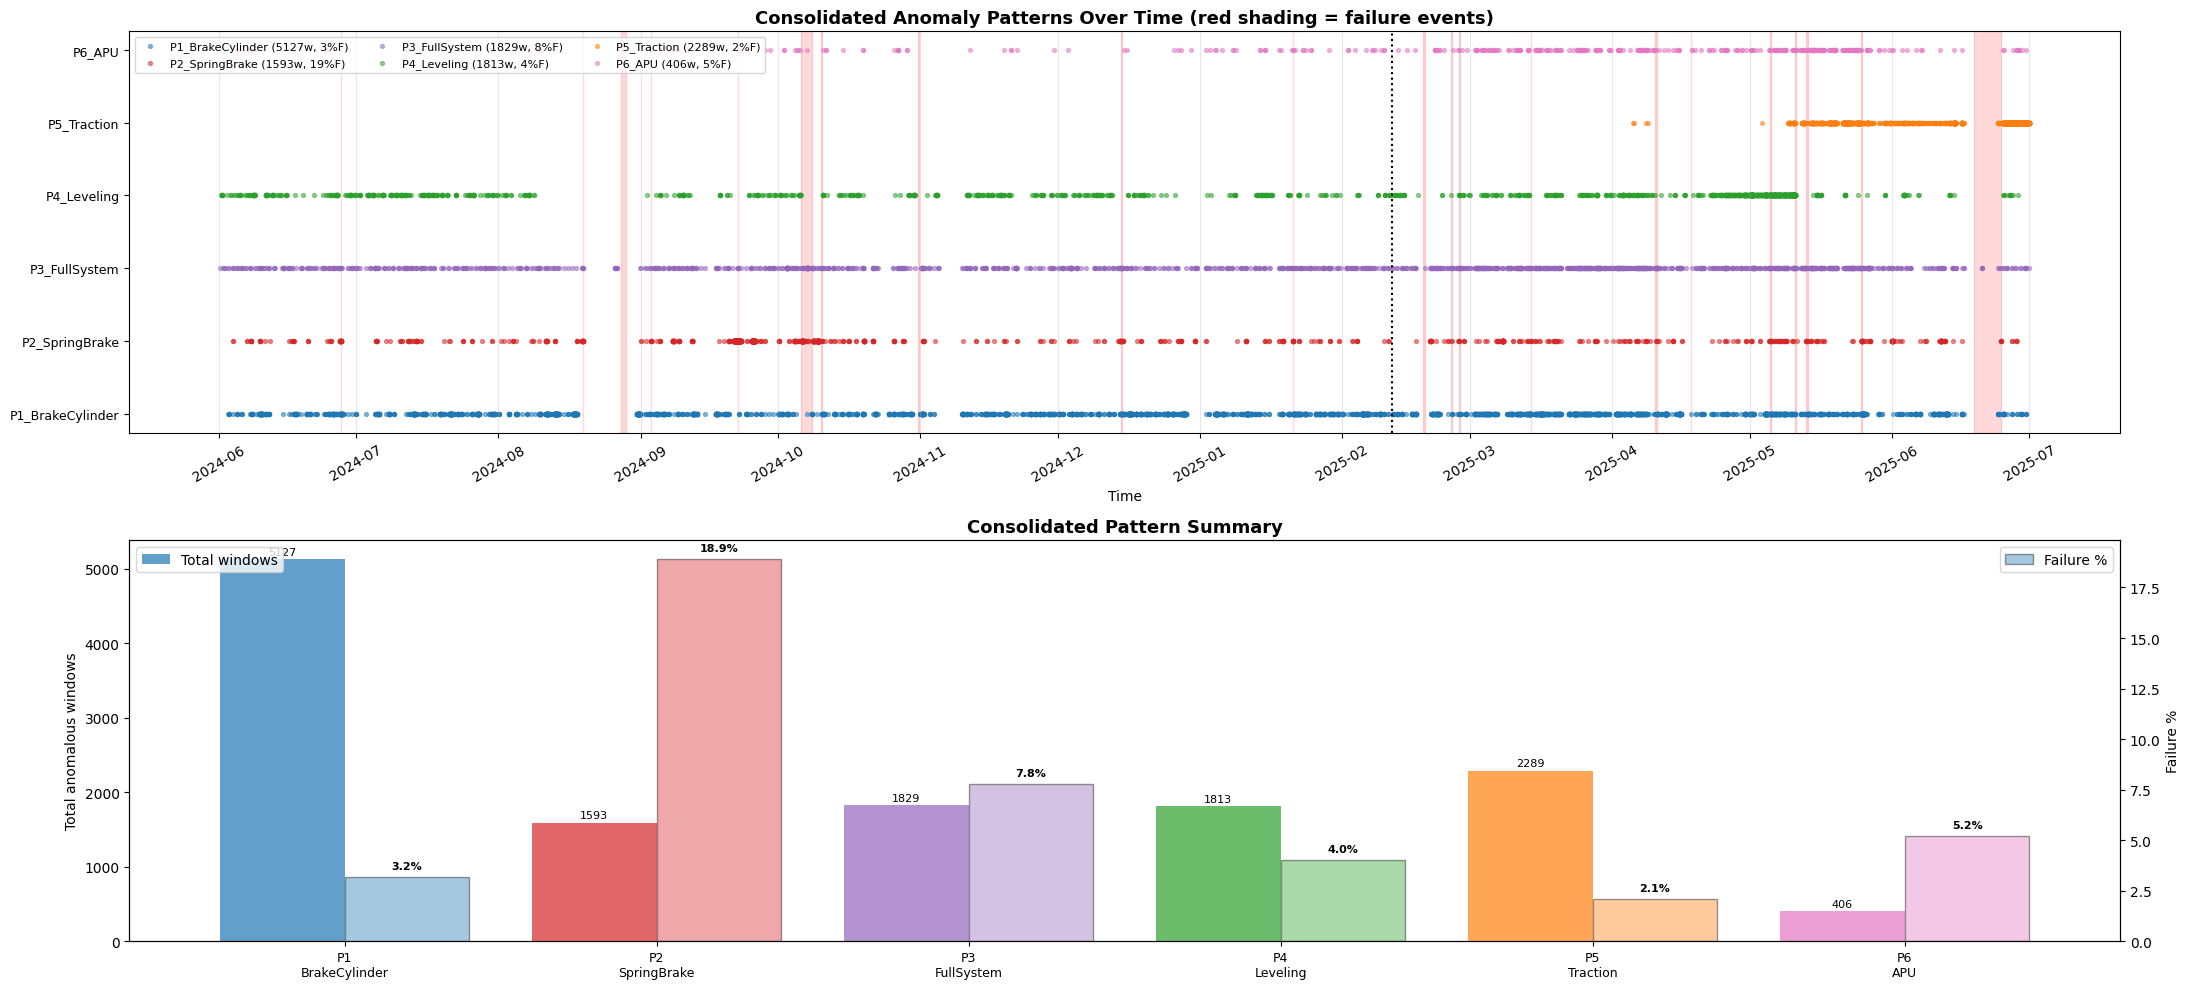

Saved consolidated_patterns_overview.png


In [17]:
# ── Consolidated patterns: timeline + bar chart ──
pattern_colors = {
    'P1_BrakeCylinder': '#1f77b4',  # blue
    'P2_SpringBrake': '#d62728',     # red
    'P3_FullSystem': '#9467bd',      # purple
    'P4_Leveling': '#2ca02c',        # green
    'P5_Traction': '#ff7f0e',        # orange
    'P6_APU': '#e377c2',             # pink
}

# Map each anomalous window to its consolidated pattern
anom_meta['pattern'] = 'unassigned'
for pname, info in consolidated.items():
    for cid in info['cluster_ids']:
        anom_meta.loc[anom_meta['cluster_clean'] == cid, 'pattern'] = pname

fig, axes = plt.subplots(2, 1, figsize=(22, 10))

# --- Top: Timeline ---
ax = axes[0]
for _, ev in fail_events.iterrows():
    ax.axvspan(ev['start'], ev['end'], alpha=0.15, color='red')

y_map = {p: i for i, p in enumerate(pattern_colors.keys())}
for pname, color in pattern_colors.items():
    mask = anom_meta['pattern'] == pname
    if mask.sum() == 0:
        continue
    pdata = anom_meta[mask]
    info = consolidated[pname]
    ax.scatter(pdata['window_end'], [y_map[pname]] * len(pdata),
              s=8, c=color, alpha=0.5,
              label=f'{pname} ({info["total_windows"]}w, {info["failure_pct"]:.0f}%F)')

ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1.5)
ax.set_yticks(list(y_map.values()))
ax.set_yticklabels(list(y_map.keys()), fontsize=9)
ax.set_xlabel('Time')
ax.set_title('Consolidated Anomaly Patterns Over Time (red shading = failure events)', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=8, ncol=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.setp(ax.get_xticklabels(), rotation=30)
ax.grid(True, alpha=0.3, axis='x')

# --- Bottom: Summary bar chart ---
ax = axes[1]
pnames = list(consolidated.keys())
windows = [consolidated[p]['total_windows'] for p in pnames]
fail_pcts = [consolidated[p]['failure_pct'] for p in pnames]
colors = [pattern_colors[p] for p in pnames]

x = np.arange(len(pnames))
width = 0.4
bars1 = ax.bar(x - width/2, windows, width, color=colors, alpha=0.7, label='Total windows')
ax2 = ax.twinx()
bars2 = ax2.bar(x + width/2, fail_pcts, width, color=colors, alpha=0.4, edgecolor='black', label='Failure %')

ax.set_xticks(x)
ax.set_xticklabels([p.replace('_', '\n') for p in pnames], fontsize=9)
ax.set_ylabel('Total anomalous windows')
ax2.set_ylabel('Failure %')
ax.set_title('Consolidated Pattern Summary', fontsize=13, fontweight='bold')

# Add value labels
for bar, val in zip(bars1, windows):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            str(val), ha='center', va='bottom', fontsize=8)
for bar, val in zip(bars2, fail_pcts):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'consolidated_patterns_overview.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved consolidated_patterns_overview.png')

In [18]:
# ── Engineer-friendly view: components & car positions per pattern ──

component_names = {
    'BRAKE_CYLINDER_PRESSURE': 'Brake Cylinder Pressure',
    'SPRING_BRAKE_PRESSURE': 'Spring Brake Pressure',
    'SPRING_BRAKE_ACTIVE': 'Spring Brake Active (binary)',
    'PROPORTIONAL_VALVE_PRESSURE': 'Proportional Valve Pressure',
    'PNEUMATIC_BRAKING_FORCE': 'Pneumatic Braking Force',
    'PNEUMATIC_BRAKE_ACTIVE': 'Pneumatic Brake Active (binary)',
    'LOAD_PRESSURE': 'Load Pressure (leveling)',
    'LOAD_SIGNAL': 'Load Signal (leveling)',
    'MAIN_RESERVOIR_PRESSURE': 'Main Reservoir Pressure (APU)',
    'COMPRESSOR_RUNNING': 'Compressor Running (binary)',
    'ENERGY_BRAKING_RESISTANCE': 'Energy Braking Resistance (traction)',
}

def parse_sensor(sensor_name):
    """Parse sensor name into car, component, bogie."""
    for prefix in ['MW1_', 'MW2_', 'MW3_', 'MW4_', 'CW1_', 'CW2_']:
        if sensor_name.startswith(prefix):
            car = prefix[:-1]
            remainder = sensor_name[len(prefix):]
            break
    else:
        return sensor_name, '', ''
    
    bogie = ''
    if remainder.endswith('_BOGIE1'):
        bogie = 'Bogie 1'
        remainder = remainder[:-7]
    elif remainder.endswith('_BOGIE2'):
        bogie = 'Bogie 2'
        remainder = remainder[:-7]
    
    component = component_names.get(remainder, remainder)
    return car, component, bogie

for pname, info in consolidated.items():
    print(f'\n{"="*70}')
    print(f'{pname}')
    print(f'{info["description"]}')
    print(f'{info["total_windows"]} anomalous windows | {info["failure_pct"]}% linked to failures')
    print(f'Linked to: {", ".join(info["linked_failure_types"])}')
    print(f'{"-"*70}')
    
    by_component = {}
    for sensor in info['sensors']:
        car, component, bogie = parse_sensor(sensor)
        by_component.setdefault(component, []).append((car, bogie))
    
    print(f'Affected components:')
    for component, locations in sorted(by_component.items()):
        cars = sorted(set(f'{car} {bogie}'.strip() for car, bogie in locations))
        print(f'  {component}:')
        print(f'    Cars: {", ".join(cars)}')

print(f'\n{"="*70}')
print('\nQuestions for Wiener Linien expert:')
print('  1. Does P2 (spring brake, 18.9% failure) match a known failure mode?')
print('  2. Is P5 (traction on MW2+MW4 only) an operational pattern or a defect?')
print('  3. Does P6 make physical sense - low reservoir pressure causing spring brake activation?')
print('  4. Is P4 (leveling-only) just passenger load variation?')


P1_BrakeCylinder
Brake cylinder & proportional valve pressure anomalies with load signal deviations
5127 anomalous windows | 3.2% linked to failures
Linked to: Brake System Failure, Compressor Module Failure, Leveling System Failure
----------------------------------------------------------------------
Affected components:
  Brake Cylinder Pressure:
    Cars: CW1 Bogie 1, CW1 Bogie 2, CW2 Bogie 1, CW2 Bogie 2, MW1 Bogie 1, MW1 Bogie 2, MW2 Bogie 1, MW2 Bogie 2, MW3 Bogie 1, MW3 Bogie 2, MW4 Bogie 1, MW4 Bogie 2
  Load Pressure (leveling):
    Cars: CW1 Bogie 1, CW1 Bogie 2, CW2 Bogie 1, CW2 Bogie 2, MW1 Bogie 1, MW1 Bogie 2, MW2 Bogie 2, MW3 Bogie 1, MW4 Bogie 1
  Load Signal (leveling):
    Cars: CW1, CW2, MW4
  Pneumatic Braking Force:
    Cars: MW1 Bogie 1, MW1 Bogie 2, MW2 Bogie 1, MW2 Bogie 2
  Proportional Valve Pressure:
    Cars: CW1 Bogie 2, MW1 Bogie 1, MW2 Bogie 1, MW3 Bogie 2, MW4 Bogie 1

P2_SpringBrake
Spring brake pressure & braking force anomalies — high failure linkag

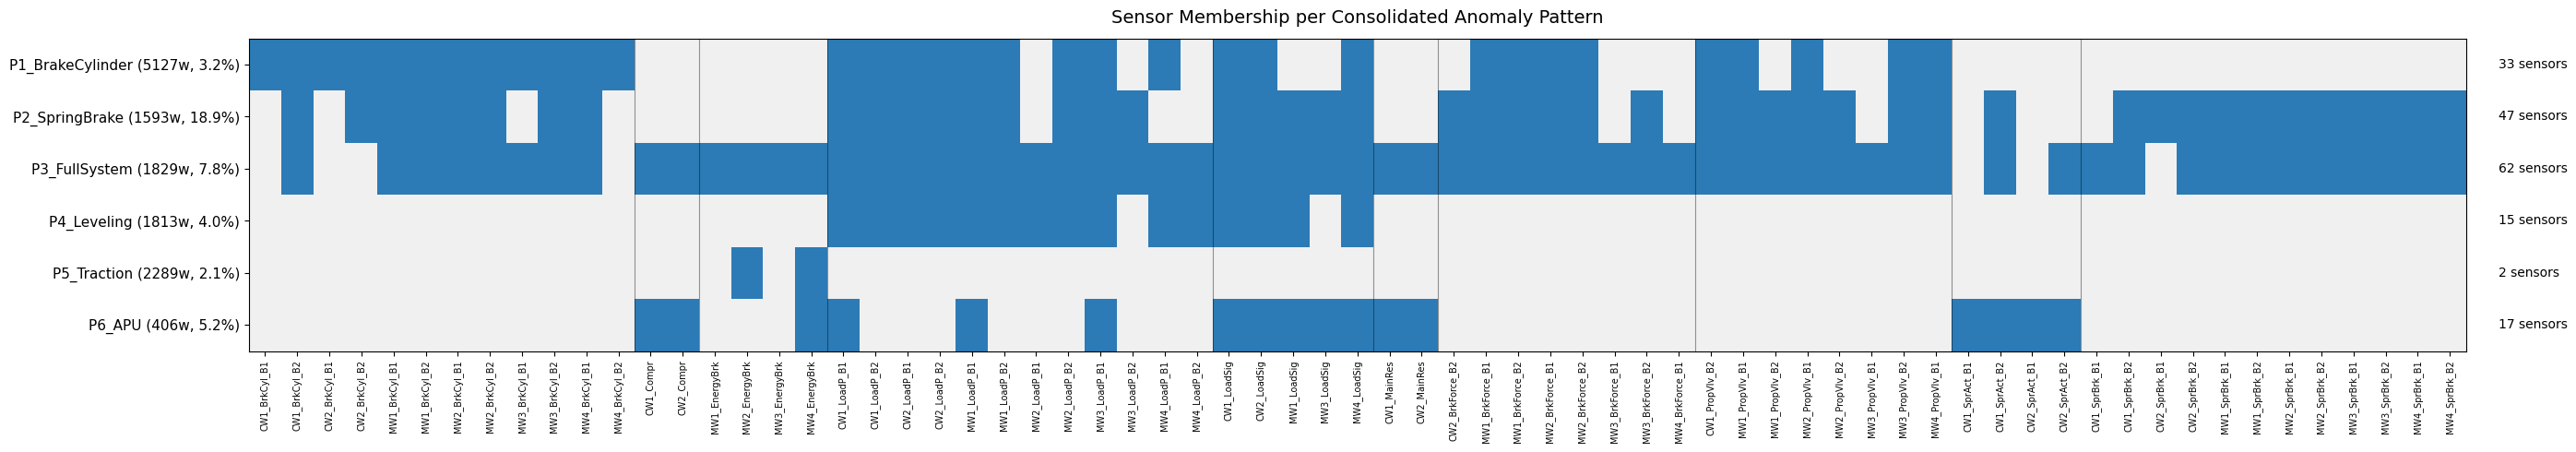

Saved to outputs/pattern_sensor_heatmap.png


In [19]:
# ── Heatmap: sensors included in each consolidated pattern ──

with open(os.path.join(OUT_DIR, 'consolidated_patterns.json'), encoding='utf-8') as f:
    cons_patterns = json.load(f)

# Collect all unique sensors across patterns
all_sensors = sorted(set(s for p in cons_patterns.values() for s in p['sensors']))
pattern_names = list(cons_patterns.keys())

# Build binary matrix: patterns x sensors
matrix = np.zeros((len(pattern_names), len(all_sensors)), dtype=int)
for i, pname in enumerate(pattern_names):
    for s in cons_patterns[pname]['sensors']:
        j = all_sensors.index(s)
        matrix[i, j] = 1

# Parse sensor into component type for grouping
def get_component(sensor):
    parts = sensor.split('_', 1)
    return parts[1] if len(parts) > 1 else sensor

# Group sensors by component type and sort
comp_order = {}
for s in all_sensors:
    comp = get_component(s)
    base = '_'.join(comp.replace('_BOGIE1','').replace('_BOGIE2','').split('_'))
    comp_order[s] = base

sorted_sensors = sorted(all_sensors, key=lambda s: (comp_order[s], s))
sort_idx = [all_sensors.index(s) for s in sorted_sensors]
matrix_sorted = matrix[:, sort_idx]

# Short labels for y-axis
y_labels = [f"{p} ({cons_patterns[p]['total_windows']}w, {cons_patterns[p]['failure_pct']:.1f}%)" for p in pattern_names]

# Short labels for x-axis: Car_Component
x_labels = []
for s in sorted_sensors:
    parts = s.split('_', 1)
    car = parts[0]
    comp = parts[1] if len(parts) > 1 else s
    comp_short = comp.replace('BRAKE_CYLINDER_PRESSURE', 'BrkCyl') \
                      .replace('SPRING_BRAKE_PRESSURE', 'SprBrk') \
                      .replace('SPRING_BRAKE_ACTIVE', 'SprAct') \
                      .replace('PROPORTIONAL_VALVE_PRESSURE', 'PropVlv') \
                      .replace('PNEUMATIC_BRAKING_FORCE', 'BrkForce') \
                      .replace('LOAD_PRESSURE', 'LoadP') \
                      .replace('LOAD_SIGNAL', 'LoadSig') \
                      .replace('MAIN_RESERVOIR_PRESSURE', 'MainRes') \
                      .replace('COMPRESSOR_RUNNING', 'Compr') \
                      .replace('ENERGY_BRAKING_RESISTANCE', 'EnergyBrk') \
                      .replace('_BOGIE1', '_B1') \
                      .replace('_BOGIE2', '_B2')
    x_labels.append(f"{car}_{comp_short}")

# Color map
from matplotlib.colors import ListedColormap
cmap = ListedColormap(['#f0f0f0', '#2c7bb6'])

fig, ax = plt.subplots(figsize=(28, 5))
im = ax.imshow(matrix_sorted, cmap=cmap, aspect='auto', interpolation='nearest')

ax.set_yticks(range(len(pattern_names)))
ax.set_yticklabels(y_labels, fontsize=11)
ax.set_xticks(range(len(sorted_sensors)))
ax.set_xticklabels(x_labels, rotation=90, fontsize=7, ha='center')
ax.set_title('Sensor Membership per Consolidated Anomaly Pattern', fontsize=14, pad=12)

# Add grid lines between component groups
prev_comp = None
for idx, s in enumerate(sorted_sensors):
    comp = comp_order[s]
    if prev_comp is not None and comp != prev_comp:
        ax.axvline(x=idx - 0.5, color='black', linewidth=0.8, alpha=0.4)
    prev_comp = comp

# Add sensor count per pattern on right side
for i, pname in enumerate(pattern_names):
    n = matrix_sorted[i].sum()
    ax.text(len(sorted_sensors) + 0.5, i, f"{n} sensors", va='center', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'pattern_sensor_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved to outputs/pattern_sensor_heatmap.png")

## 6. Rebuild Anomalous Windows with Full Context

Rebuild the anomaly detection from NB04 but keep **min, max, mean, std** per window — not just z-score binary activation. This addresses feedback #1 (use max/min) and #13 (give more context).

In [2]:
# Combine train+test for full-period analysis
all_data = pd.concat([train_sup, test_sup], ignore_index=True)
all_data['window_end'] = pd.to_datetime(all_data['window_end'])
all_data = all_data.sort_values('window_end').reset_index(drop=True)
print(f"Full dataset: {all_data.shape}")

# Compute z-scores per feature (train stats)
train_means = train_sup[feature_cols].mean()
train_stds = train_sup[feature_cols].std().replace(0, 1)
z_scores = (all_data[feature_cols] - train_means) / train_stds

# Identify anomalous windows: |z| > 3 in at least 5 features
anomaly_mask = (z_scores.abs() > 3)
n_anomalous_features = anomaly_mask.sum(axis=1)
is_anomalous = n_anomalous_features >= 5
anomaly_idx = all_data.index[is_anomalous]

print(f"Anomalous windows: {len(anomaly_idx)} / {len(all_data)} ({100*len(anomaly_idx)/len(all_data):.1f}%)")
print(f"  In failure: {all_data.loc[anomaly_idx, 'label'].sum()}")
print(f"  In normal: {(~all_data.loc[anomaly_idx, 'label'].astype(bool)).sum()}")

Full dataset: (64522, 343)


Anomalous windows: 12237 / 64522 (19.0%)
  In failure: 731
  In normal: 11506


In [3]:
# Build activation matrix and cluster assignments (reproduce NB04)
activation_matrix = anomaly_mask.loc[anomaly_idx].astype(int)

# Cluster using Jaccard distance + Ward linkage on feature co-activation
dist = pdist(activation_matrix.T.values, metric='jaccard')
Z = linkage(dist, method='average')
cluster_labels = fcluster(Z, t=0.7, criterion='distance')

# Map features to clusters
feat_to_cluster = {}
for feat, cl in zip(feature_cols, cluster_labels):
    feat_to_cluster[feat] = cl

# Build cluster info
clusters = {}
for feat, cl in feat_to_cluster.items():
    if cl not in clusters:
        clusters[cl] = []
    clusters[cl].append(feat)

print(f"Number of clusters: {len(clusters)}")
for cl_id in sorted(clusters.keys()):
    feats = clusters[cl_id]
    # Get windows where this cluster is active
    cl_active = activation_matrix[feats].any(axis=1)
    n_windows = cl_active.sum()
    n_fail = all_data.loc[anomaly_idx[cl_active], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_windows, 1)
    sensors = set(f.rsplit('_', 1)[0] for f in feats if any(f.endswith(s) for s in ['_min','_max','_mean','_sum']))
    if not sensors:
        sensors = set(f.rsplit('_', 1)[0] for f in feats)
    print(f"  C{cl_id}: {len(feats)} features, {len(sensors)} sensors, {n_windows} windows, {fail_pct:.1f}% failure")

Number of clusters: 51
  C1: 119 features, 41 sensors, 0 windows, 0.0% failure
  C2: 8 features, 8 sensors, 57 windows, 22.8% failure
  C3: 2 features, 2 sensors, 34 windows, 2.9% failure
  C4: 4 features, 4 sensors, 28 windows, 3.6% failure
  C5: 1 features, 1 sensors, 74 windows, 16.2% failure
  C6: 1 features, 1 sensors, 2 windows, 0.0% failure
  C7: 3 features, 3 sensors, 22 windows, 40.9% failure
  C8: 2 features, 2 sensors, 3 windows, 66.7% failure
  C9: 1 features, 1 sensors, 1 windows, 0.0% failure
  C10: 1 features, 1 sensors, 23 windows, 13.0% failure
  C11: 15 features, 12 sensors, 2861 windows, 5.0% failure
  C12: 1 features, 1 sensors, 4027 windows, 9.9% failure
  C13: 1 features, 1 sensors, 76 windows, 11.8% failure
  C14: 1 features, 1 sensors, 35 windows, 11.4% failure
  C15: 5 features, 5 sensors, 458 windows, 7.4% failure
  C16: 2 features, 2 sensors, 333 windows, 4.8% failure
  C17: 4 features, 4 sensors, 532 windows, 12.2% failure
  C18: 1 features, 1 sensors, 464 w

## 7. Top-10 Features per Cluster with Numerical Statistics

For each cluster: show the top-10 features ranked by activation frequency, with **min, max, mean, std** of actual values (not z-scores). Addresses feedback #7, #8, #10.

In [4]:
def cluster_top_features(cl_id, feats, top_n=10):
    """Show top-N features for a cluster with full numerical statistics."""
    cl_active = activation_matrix[feats].any(axis=1)
    active_windows = anomaly_idx[cl_active]
    
    # Activation frequency per feature
    act_freq = activation_matrix.loc[active_windows, feats].sum().sort_values(ascending=False)
    top_feats = act_freq.head(top_n).index.tolist()
    
    # Raw values for active windows vs all windows
    rows = []
    for feat in top_feats:
        active_vals = all_data.loc[active_windows, feat]
        all_vals = all_data[feat]
        normal_vals = all_data.loc[all_data['label'] == 0, feat]
        rows.append({
            'Feature': feat,
            'Activations': int(act_freq[feat]),
            'Act%': f"{100*act_freq[feat]/len(active_windows):.0f}%",
            'Anomaly_Mean': f"{active_vals.mean():.3f}",
            'Anomaly_Std': f"{active_vals.std():.3f}",
            'Anomaly_Min': f"{active_vals.min():.3f}",
            'Anomaly_Max': f"{active_vals.max():.3f}",
            'Normal_Mean': f"{normal_vals.mean():.3f}",
            'Shift': f"{active_vals.mean() - normal_vals.mean():+.3f}",
        })
    
    df = pd.DataFrame(rows)
    n_fail = all_data.loc[active_windows, 'label'].sum()
    fail_pct = 100 * n_fail / max(len(active_windows), 1)
    print(f"\n{'='*100}")
    print(f"CLUSTER {cl_id} | {len(feats)} features | {len(active_windows)} windows | {n_fail} failures ({fail_pct:.1f}%)")
    print(f"{'='*100}")
    print(df.to_string(index=False))
    return df

# Show top-10 for each cluster
cluster_stats = {}
for cl_id in sorted(clusters.keys()):
    feats = clusters[cl_id]
    if len(feats) >= 3:  # skip tiny clusters
        cluster_stats[cl_id] = cluster_top_features(cl_id, feats)


CLUSTER 1 | 119 features | 0 windows | 0 failures (0.0%)
                                   Feature  Activations Act% Anomaly_Mean Anomaly_Std Anomaly_Min Anomaly_Max Normal_Mean Shift
      CW1_SPRING_BRAKE_PRESSURE_BOGIE1_min            0 nan%          nan         nan         nan         nan       0.539  +nan
      CW2_SPRING_BRAKE_PRESSURE_BOGIE1_min            0 nan%          nan         nan         nan         nan       0.535  +nan
CW1_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_min            0 nan%          nan         nan         nan         nan       0.049  +nan
CW1_PROPORTIONAL_VALVE_PRESSURE_BOGIE2_min            0 nan%          nan         nan         nan         nan       0.096  +nan
CW2_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_min            0 nan%          nan         nan         nan         nan       0.048  +nan
CW2_PROPORTIONAL_VALVE_PRESSURE_BOGIE2_min            0 nan%          nan         nan         nan         nan       0.093  +nan
MW1_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_min    


CLUSTER 11 | 15 features | 2861 windows | 142 failures (5.0%)
                               Feature  Activations Act% Anomaly_Mean Anomaly_Std Anomaly_Min Anomaly_Max Normal_Mean  Shift
CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min         2682  94%        0.282       0.067       0.000       0.301       0.019 +0.262
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min         2660  93%        0.515       0.123       0.000       0.551       0.036 +0.479
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min         2654  93%        0.513       0.126       0.000       0.551       0.037 +0.477
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min         2651  93%        0.279       0.071       0.000       0.301       0.019 +0.261
CW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min         2646  92%        0.511       0.128       0.000       0.549       0.034 +0.476
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_min         2643  92%        0.508       0.136       0.000       0.619       0.037 +0.471
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min         2643  92%      


CLUSTER 26 | 4 features | 1358 windows | 115 failures (8.5%)
             Feature  Activations Act% Anomaly_Mean Anomaly_Std Anomaly_Min Anomaly_Max Normal_Mean    Shift
 CW1_LOAD_SIGNAL_sum          884  65%      141.347      76.805       1.000     343.000      21.676 +119.671
CW1_LOAD_SIGNAL_mean          864  64%        0.497       0.266       0.003       1.000       0.066   +0.431
 CW1_LOAD_SIGNAL_min          732  54%        0.308       0.321       0.000       1.000       0.023   +0.285
 CW1_LOAD_SIGNAL_max          550  41%        0.663       0.271       0.218       1.000       0.148   +0.515

CLUSTER 27 | 6 features | 528 windows | 78 failures (14.8%)
                         Feature  Activations Act% Anomaly_Mean Anomaly_Std Anomaly_Min Anomaly_Max Normal_Mean  Shift
 CW1_MAIN_RESERVOIR_PRESSURE_min          491  93%        0.390       0.237       0.000       0.929       0.866 -0.476
 CW2_MAIN_RESERVOIR_PRESSURE_min          483  91%        0.401       0.243       0.000       


CLUSTER 33 | 3 features | 1234 windows | 100 failures (8.1%)
                      Feature  Activations Act% Anomaly_Mean Anomaly_Std Anomaly_Min Anomaly_Max Normal_Mean  Shift
MW1_LOAD_PRESSURE_BOGIE2_mean          880  71%        0.287       0.098       0.000       0.440       0.235 +0.052
 MW2_LOAD_PRESSURE_BOGIE2_min          587  48%        0.254       0.083       0.000       0.367       0.227 +0.027
MW2_LOAD_PRESSURE_BOGIE2_mean          540  44%        0.304       0.070       0.000       0.408       0.256 +0.048

CLUSTER 34 | 7 features | 1658 windows | 51 failures (3.1%)
                      Feature  Activations Act% Anomaly_Mean Anomaly_Std Anomaly_Min Anomaly_Max Normal_Mean   Shift
          CW2_LOAD_SIGNAL_sum          968  58%       83.844      60.855       0.000     342.000      11.761 +72.083
         CW2_LOAD_SIGNAL_mean          956  58%        0.264       0.194       0.000       1.000       0.035  +0.228
          CW2_LOAD_SIGNAL_min          882  53%        0.146  


CLUSTER 47 | 10 features | 4856 windows | 383 failures (7.9%)
                               Feature  Activations Act% Anomaly_Mean Anomaly_Std Anomaly_Min Anomaly_Max Normal_Mean  Shift
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max         3612  74%        0.096       0.165       0.000       0.664       0.513 -0.417
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_max         3214  66%        0.157       0.219       0.000       0.736       0.508 -0.351
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max         3037  63%        0.168       0.219       0.000       0.717       0.508 -0.340
MW4_BRAKE_CYLINDER_PRESSURE_BOGIE1_max         2997  62%        0.164       0.210       0.000       0.727       0.473 -0.310
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_max         2465  51%        0.202       0.211       0.000       0.604       0.474 -0.273
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE1_max         2436  50%        0.212       0.224       0.000       0.694       0.514 -0.301
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_max         2426  50%      

## 8. C7 & C8 Deep Dive: Variance Trends and Back-Calculations

Feedback #9, #11, #15: Check C7 and C8 top features — is variance going up? Shifting up/down? Back-calculate to raw sensor values.

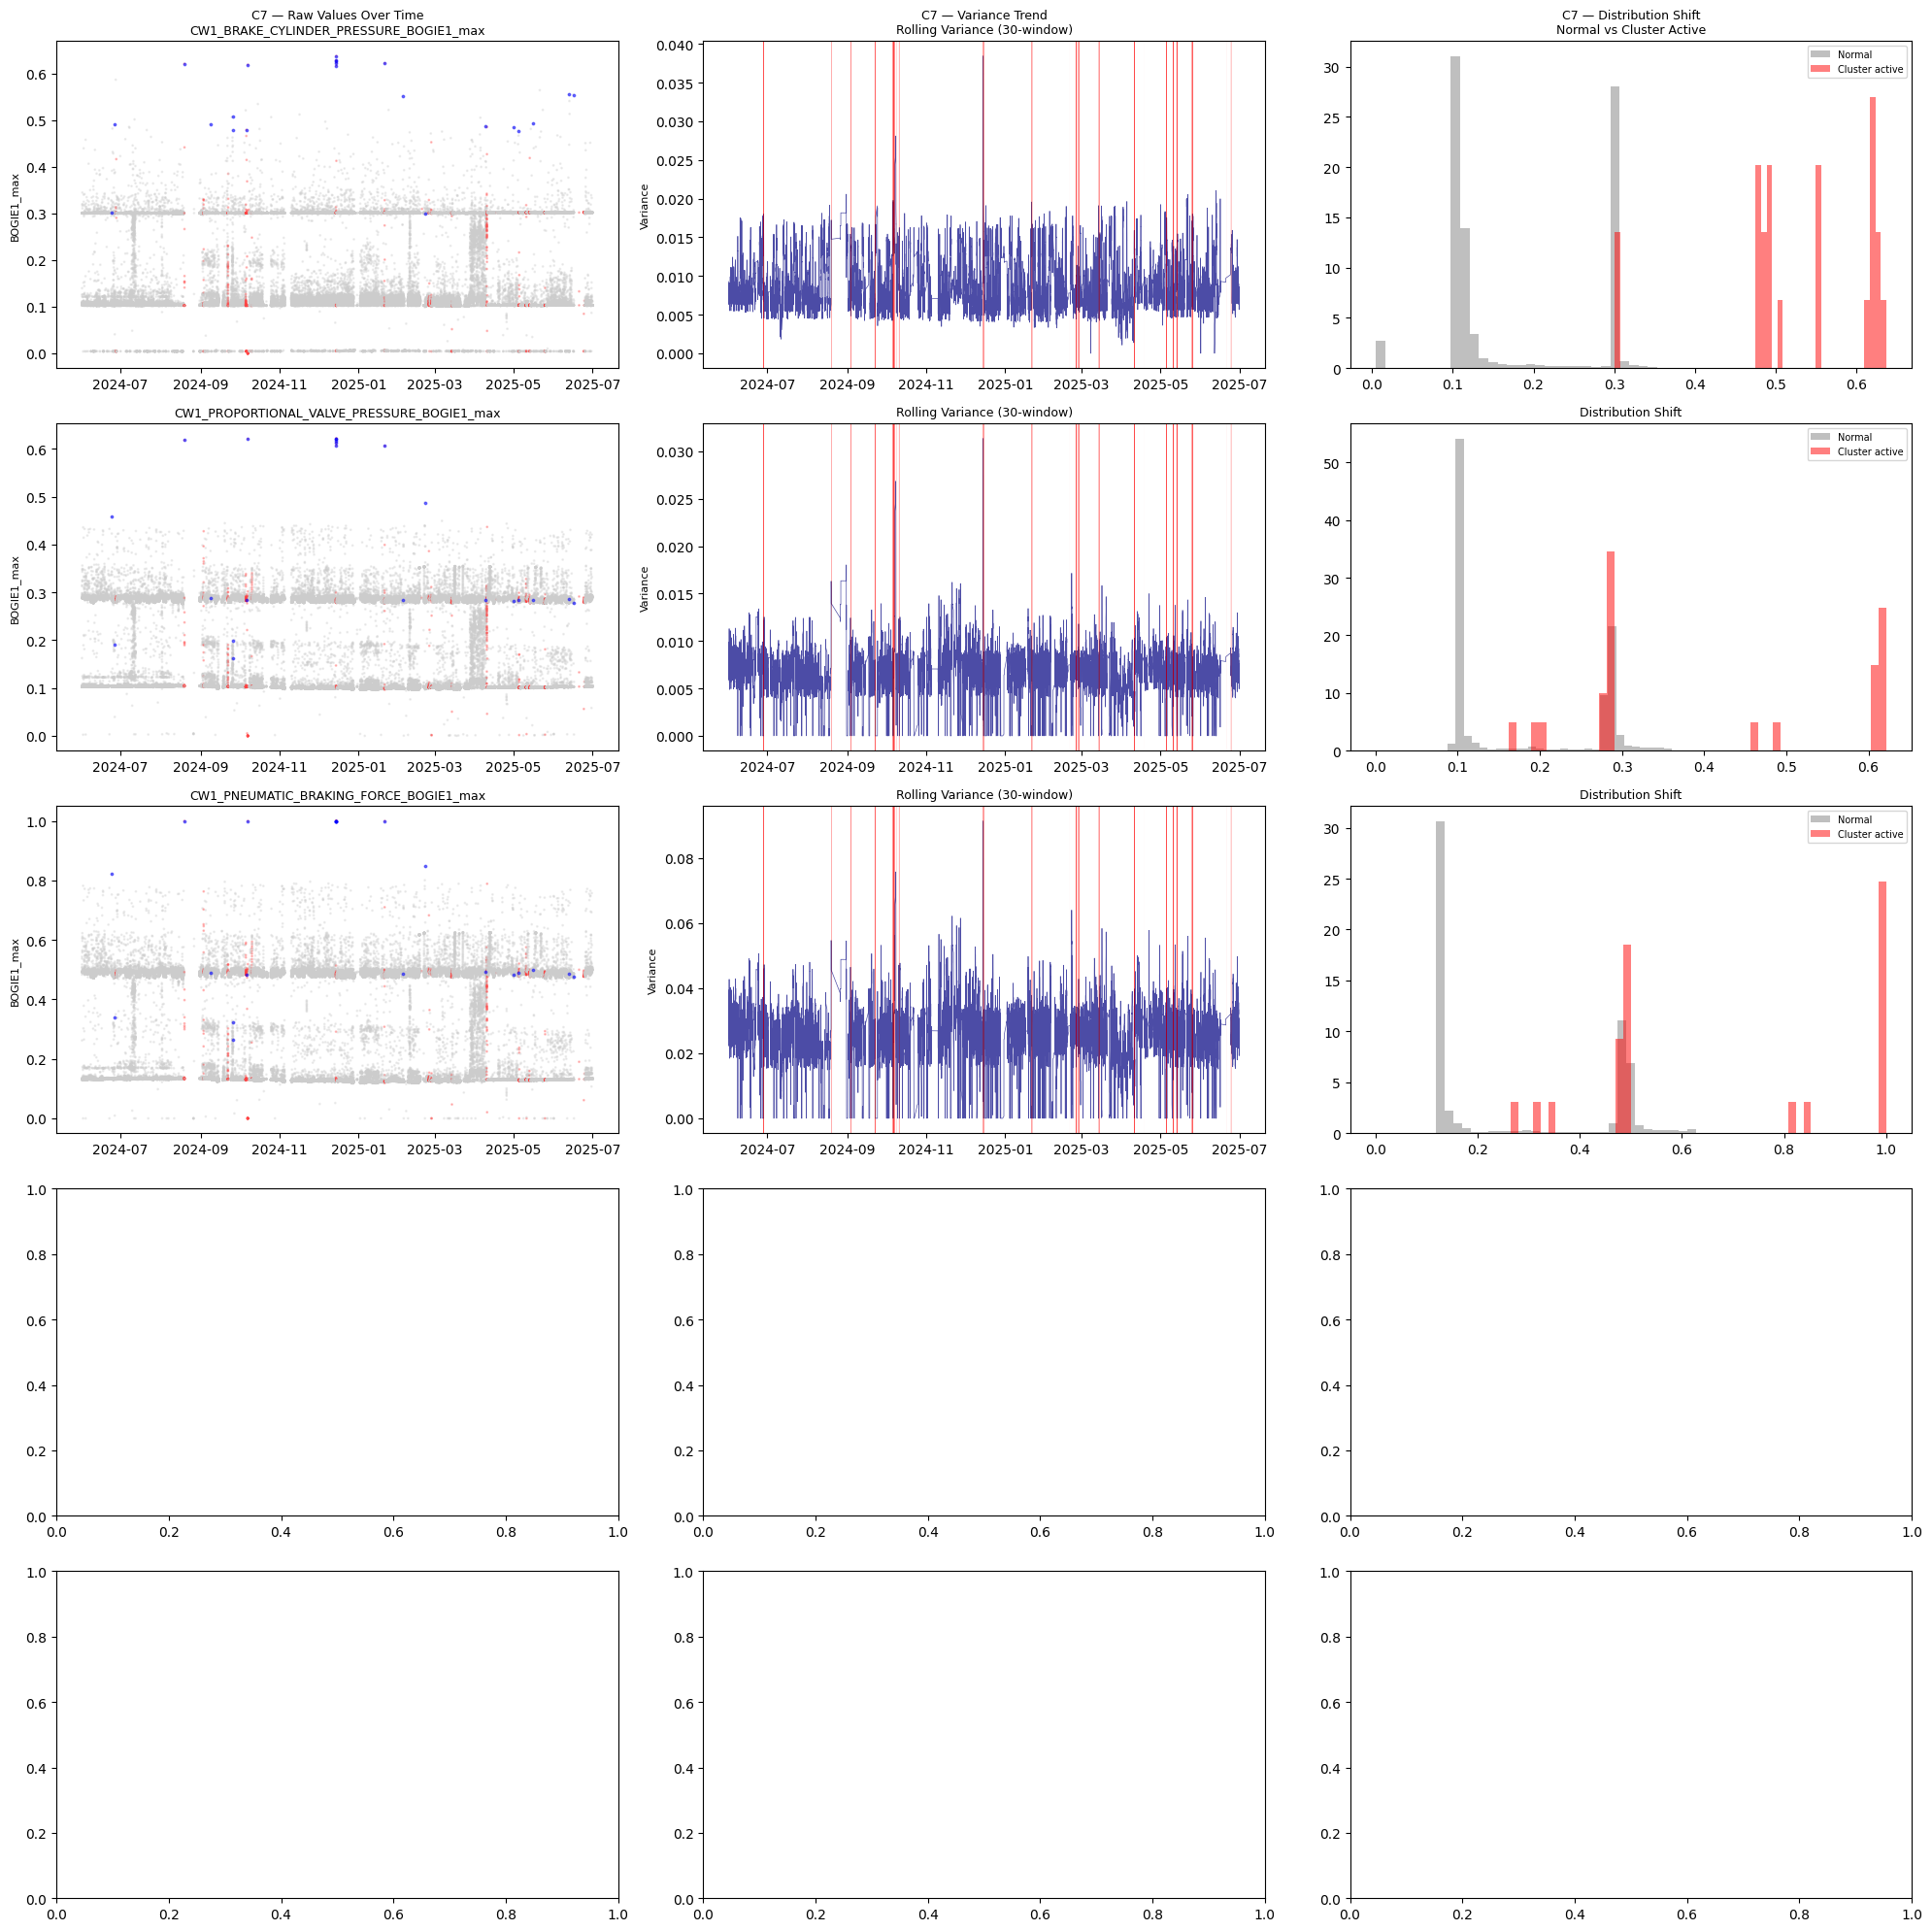


C7 Back-Calculations — Top 5 features:
Feature                                             Normal_Mean    Anom_Mean      Shift   Normal_Std     Anom_Std  Var_Ratio
------------------------------------------------------------------------------------------------------------------------
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max                   0.1778       0.5291    +0.3513       0.0971       0.0963       0.98x
CW1_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max               0.1776       0.4078    +0.2302       0.0918       0.1751       3.64x
CW1_PNEUMATIC_BRAKING_FORCE_BOGIE1_max                   0.2777       0.6810    +0.4033       0.1793       0.2775       2.40x


In [5]:
def deep_dive_cluster(cl_id, feats, n_top=5):
    """Deep dive: variance over time, shifting, back-calculations for a cluster."""
    cl_active = activation_matrix[feats].any(axis=1)
    active_windows = anomaly_idx[cl_active]
    
    # Top features by activation frequency
    act_freq = activation_matrix.loc[active_windows, feats].sum().sort_values(ascending=False)
    top_feats = act_freq.head(n_top).index.tolist()
    
    fig, axes = plt.subplots(n_top, 3, figsize=(20, 4*n_top))
    if n_top == 1:
        axes = axes.reshape(1, -1)
    
    for i, feat in enumerate(top_feats):
        vals = all_data[feat]
        times = all_data['window_end']
        labels = all_data['label']
        
        # Left: Raw values over time with failure regions
        ax = axes[i, 0]
        ax.scatter(times, vals, c=labels.map({0: '#cccccc', 1: '#ff4444'}), s=1, alpha=0.3)
        # Highlight anomalous windows for this cluster
        ax.scatter(times.loc[active_windows], vals.loc[active_windows], 
                   c='blue', s=3, alpha=0.5, label='Cluster active')
        ax.set_ylabel(feat.split('_')[-2] + '_' + feat.split('_')[-1] if '_' in feat else feat, fontsize=8)
        ax.set_title(f'{feat}', fontsize=9)
        if i == 0:
            ax.set_title(f'C{cl_id} — Raw Values Over Time\n{feat}', fontsize=9)
        
        # Middle: Rolling variance (30-window rolling)
        ax = axes[i, 1]
        rolling_var = vals.rolling(30, min_periods=10).var()
        ax.plot(times, rolling_var, color='navy', linewidth=0.5, alpha=0.7)
        # Mark failure periods
        fail_times = times[labels == 1]
        for ft in fail_times:
            ax.axvline(ft, color='red', alpha=0.02, linewidth=0.5)
        ax.set_title(f'Rolling Variance (30-window)' if i > 0 else f'C{cl_id} — Variance Trend\nRolling Variance (30-window)', fontsize=9)
        ax.set_ylabel('Variance', fontsize=8)
        
        # Right: Distribution comparison (normal vs anomalous)
        ax = axes[i, 2]
        normal_vals = vals[labels == 0]
        anomaly_vals = vals.loc[active_windows]
        ax.hist(normal_vals, bins=50, alpha=0.5, color='gray', label='Normal', density=True)
        ax.hist(anomaly_vals, bins=50, alpha=0.5, color='red', label='Cluster active', density=True)
        ax.legend(fontsize=7)
        ax.set_title(f'Distribution Shift' if i > 0 else f'C{cl_id} — Distribution Shift\nNormal vs Cluster Active', fontsize=9)
        
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f'deep_dive_C{cl_id}.png'), dpi=150, bbox_inches='tight')
    plt.show()
    
    # Numerical back-calculations
    print(f"\nC{cl_id} Back-Calculations — Top {n_top} features:")
    print(f"{'Feature':<50} {'Normal_Mean':>12} {'Anom_Mean':>12} {'Shift':>10} {'Normal_Std':>12} {'Anom_Std':>12} {'Var_Ratio':>10}")
    print('-'*120)
    for feat in top_feats:
        normal_vals = all_data.loc[all_data['label'] == 0, feat]
        anom_vals = all_data.loc[active_windows, feat]
        var_ratio = anom_vals.var() / max(normal_vals.var(), 1e-10)
        shift = anom_vals.mean() - normal_vals.mean()
        print(f"{feat:<50} {normal_vals.mean():>12.4f} {anom_vals.mean():>12.4f} {shift:>+10.4f} {normal_vals.std():>12.4f} {anom_vals.std():>12.4f} {var_ratio:>10.2f}x")

# Deep dive C7
if 7 in clusters:
    deep_dive_cluster(7, clusters[7])
else:
    print("C7 not found — checking available cluster IDs:", sorted(clusters.keys())[:20])

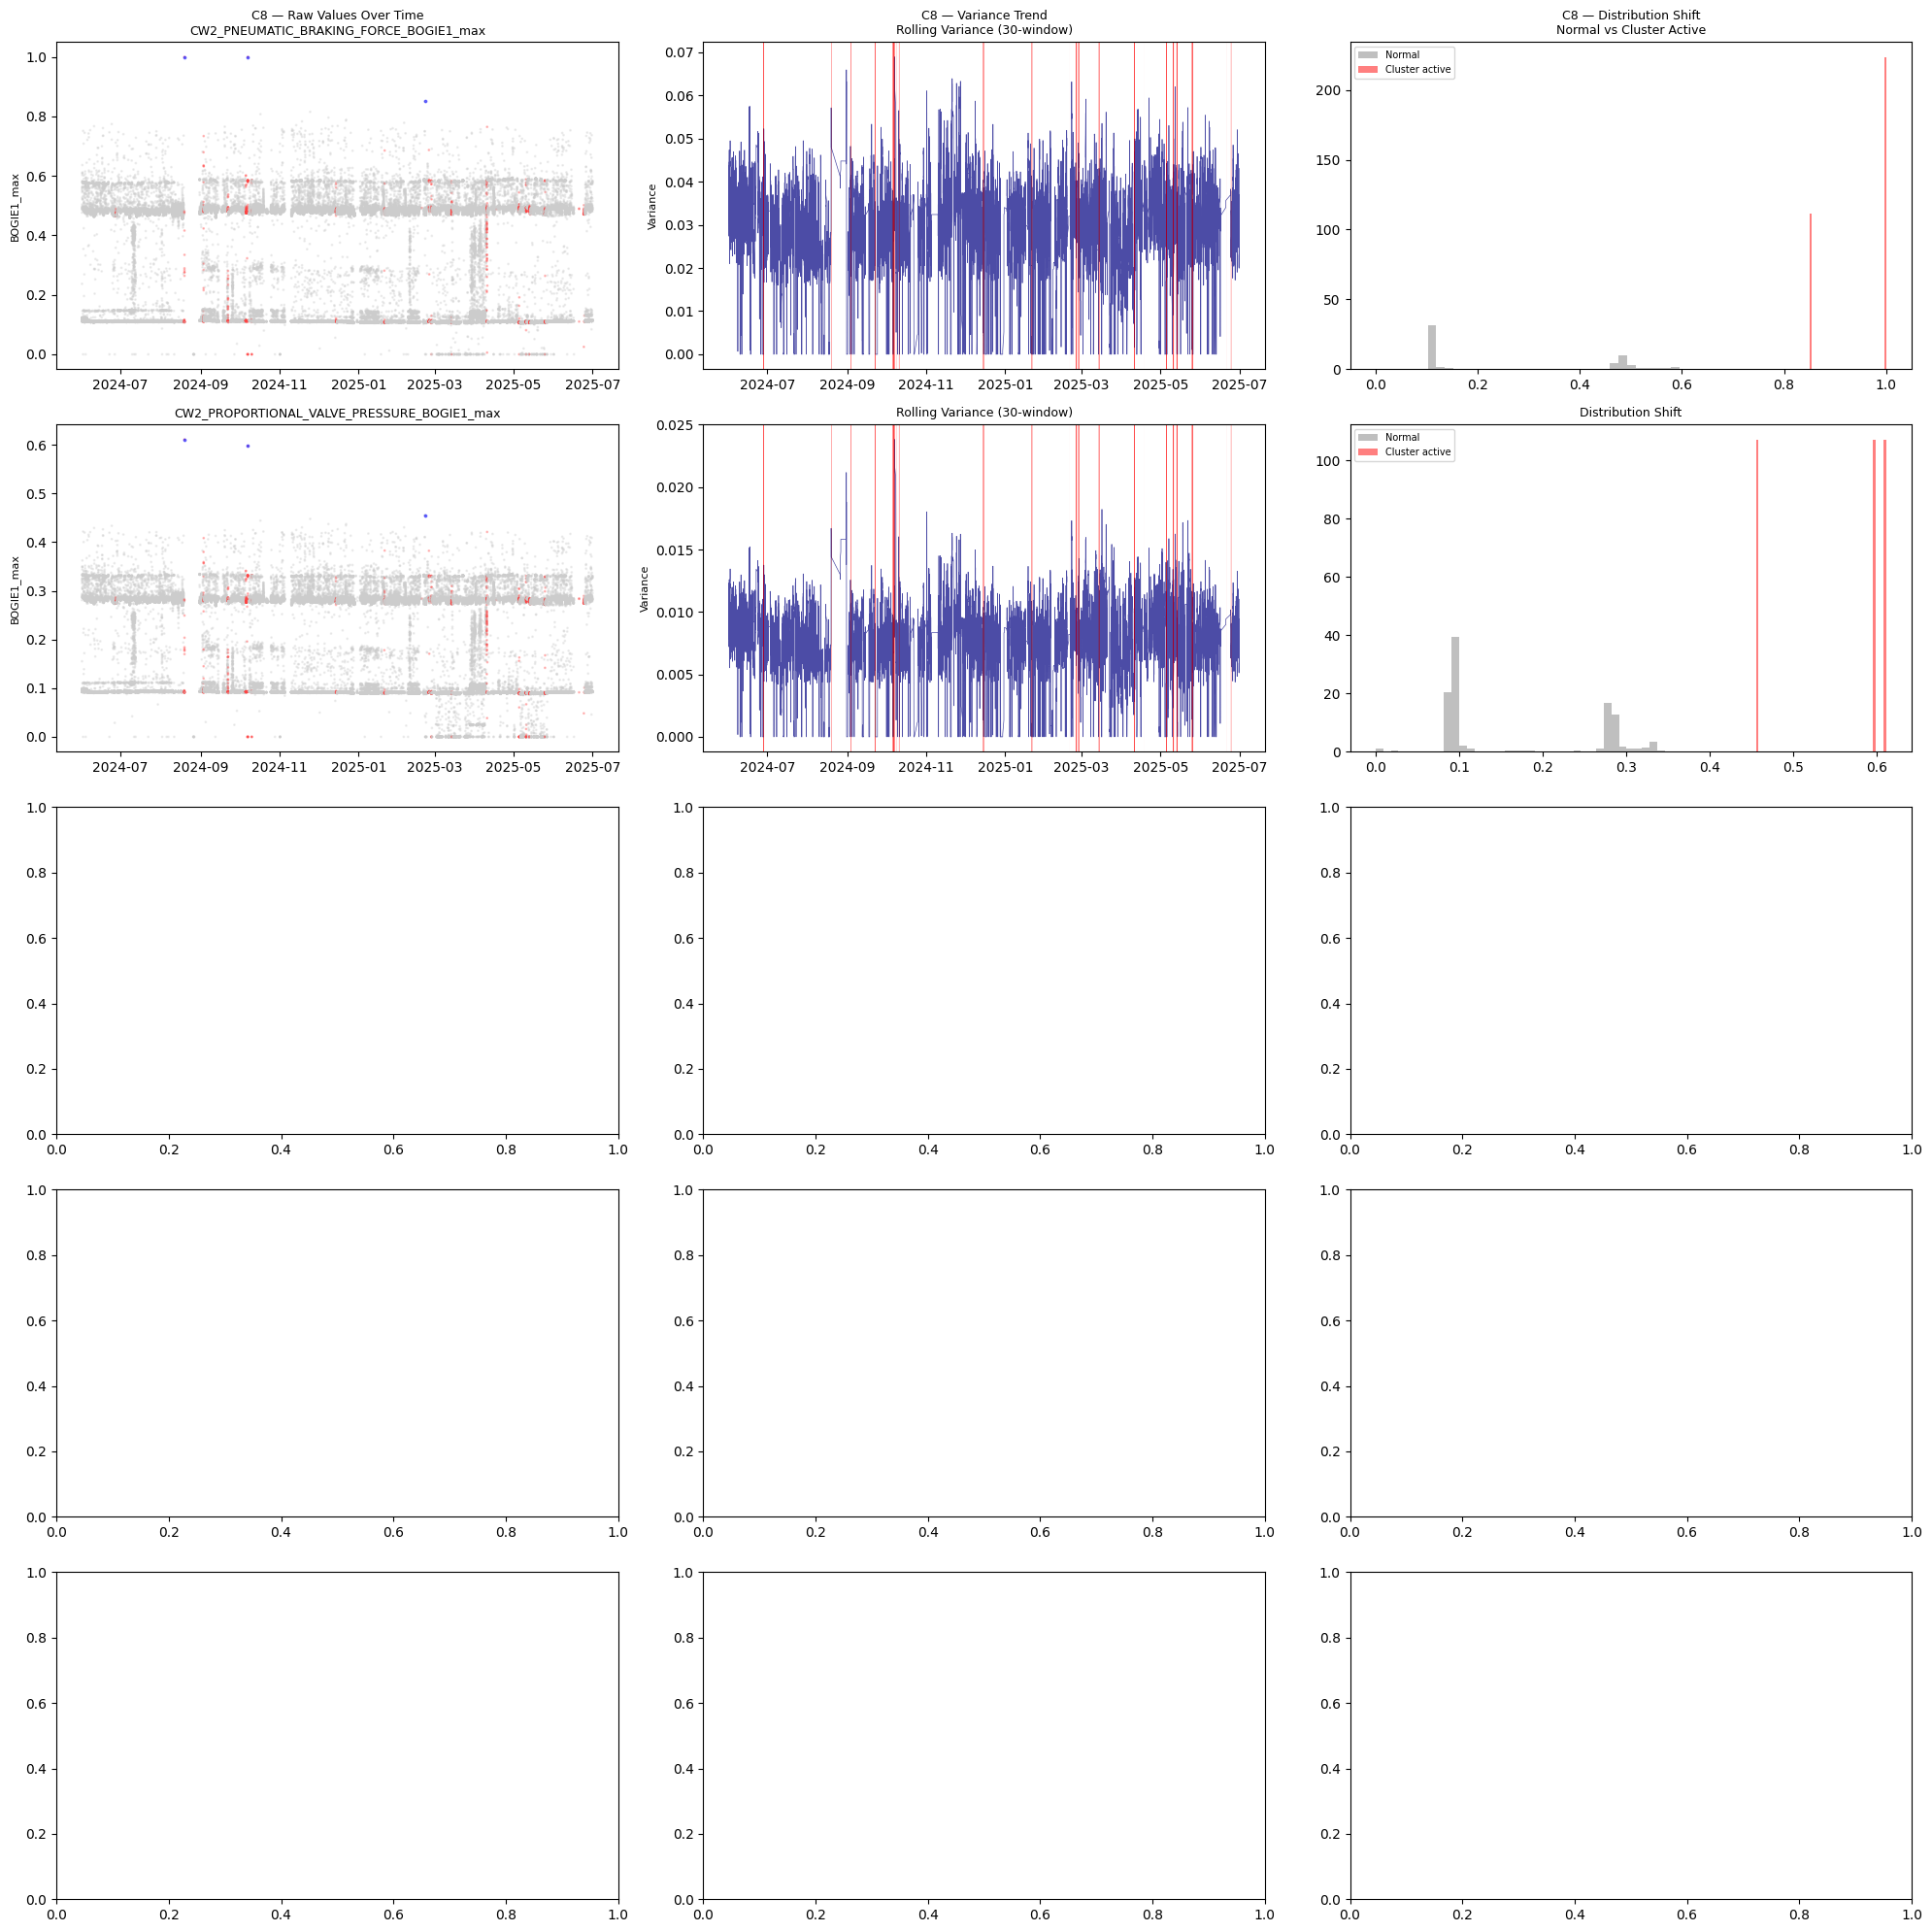


C8 Back-Calculations — Top 5 features:
Feature                                             Normal_Mean    Anom_Mean      Shift   Normal_Std     Anom_Std  Var_Ratio
------------------------------------------------------------------------------------------------------------------------
CW2_PNEUMATIC_BRAKING_FORCE_BOGIE1_max                   0.2658       0.9502    +0.6844       0.1906       0.0863       0.20x
CW2_PROPORTIONAL_VALVE_PRESSURE_BOGIE1_max               0.1686       0.5546    +0.3860       0.0980       0.0864       0.78x


In [6]:
# Deep dive C8
if 8 in clusters:
    deep_dive_cluster(8, clusters[8])
else:
    print("C8 not found — checking available cluster IDs:", sorted(clusters.keys())[:20])

## 9. Unfold: Check 2 Days of Raw Sensor Data

Pick 2 days — one with a failure event, one normal — and plot the raw sensor values for C7 and C8 top features. Addresses feedback #5, #6.

Selected failure day: 2025-01-21 (51 failure windows)
Selected normal day: 2024-12-19 (0 failure windows)


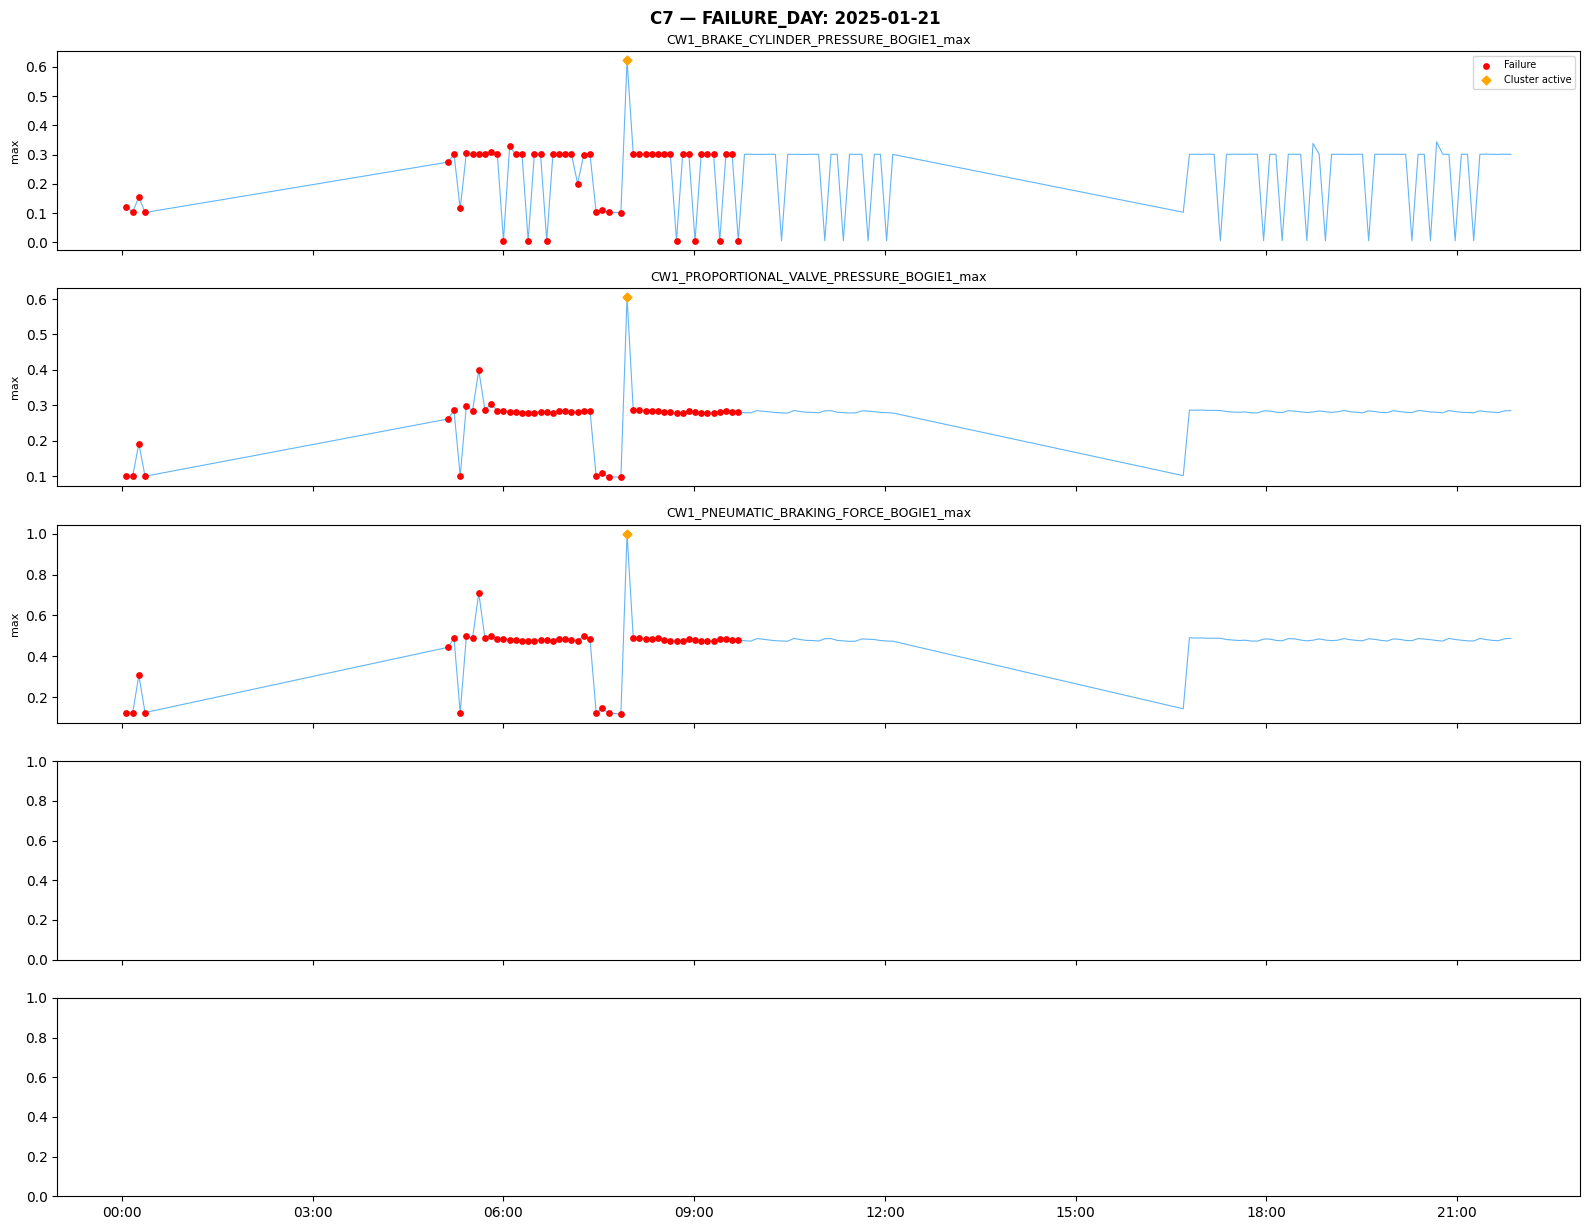

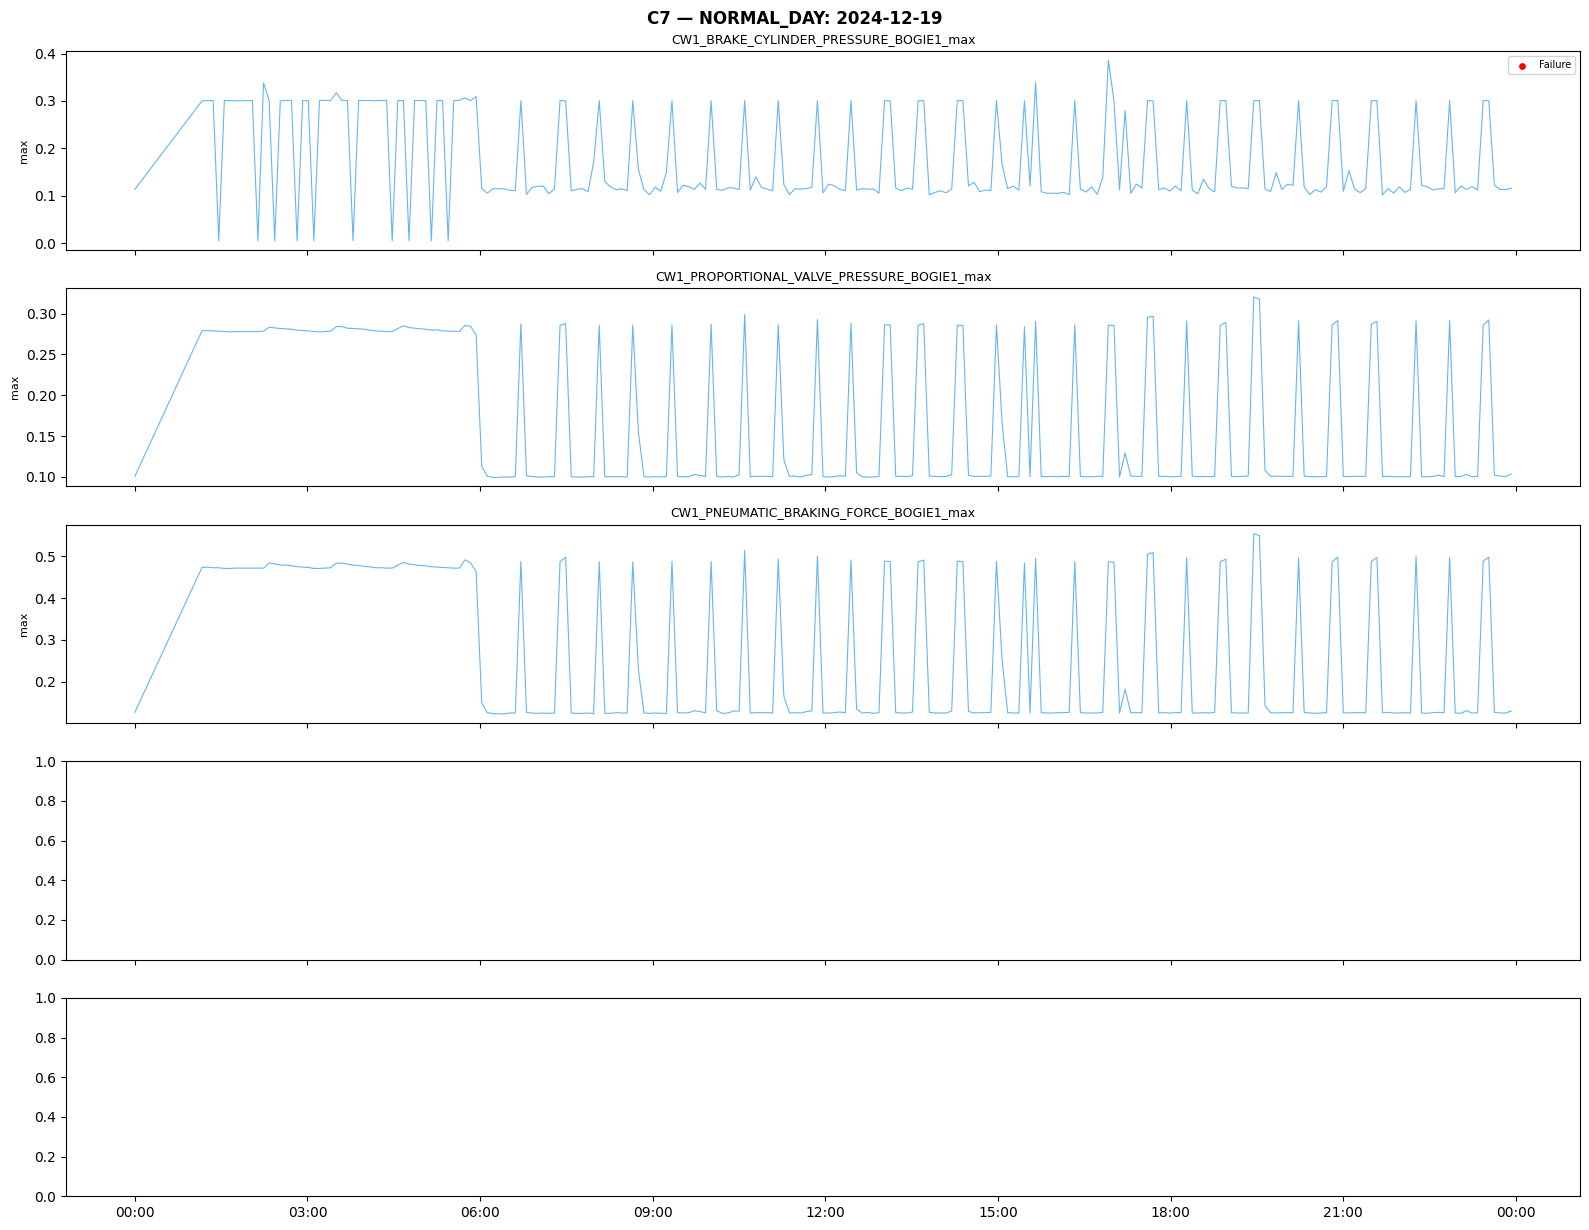

In [8]:
# Find a failure day and a normal day
all_data['date'] = all_data['window_end'].dt.date
daily_fail = all_data.groupby('date')['label'].sum()
fail_days = daily_fail[daily_fail > 5].index.tolist()
normal_days = daily_fail[daily_fail == 0].index.tolist()

failure_day = fail_days[len(fail_days)//2] if fail_days else None  # pick middle failure day
normal_day = normal_days[len(normal_days)//2] if normal_days else None  # pick middle normal day

print(f"Selected failure day: {failure_day} ({daily_fail.get(failure_day, 0)} failure windows)")
print(f"Selected normal day: {normal_day} ({daily_fail.get(normal_day, 0)} failure windows)")

def plot_day(day, day_label, cluster_id, feats, n_top=5):
    """Plot raw sensor values for a single day for top features of a cluster."""
    day_data = all_data[all_data['date'] == day].copy()
    if len(day_data) == 0:
        print(f"No data for {day}")
        return
    
    # Top features by activation
    cl_active = activation_matrix[feats].any(axis=1)
    active_windows = anomaly_idx[cl_active]
    act_freq = activation_matrix.loc[active_windows, feats].sum().sort_values(ascending=False)
    top_feats = act_freq.head(n_top).index.tolist()
    
    fig, axes = plt.subplots(n_top, 1, figsize=(16, 2.5*n_top), sharex=True)
    if n_top == 1:
        axes = [axes]
    
    for i, feat in enumerate(top_feats):
        ax = axes[i]
        times = day_data['window_end']
        vals = day_data[feat]
        colors = day_data['label'].map({0: '#2196F3', 1: '#ff4444'})
        
        ax.plot(times, vals, color='#2196F3', linewidth=0.8, alpha=0.7)
        ax.scatter(times[day_data['label']==1], vals[day_data['label']==1], 
                   c='red', s=15, zorder=5, label='Failure')
        
        # Mark anomalous windows for this cluster
        day_active = day_data.index.isin(active_windows)
        if day_active.any():
            ax.scatter(times[day_active], vals[day_active], 
                       c='orange', s=20, marker='D', zorder=6, label='Cluster active')
        
        ax.set_ylabel(feat.rsplit('_', 1)[-1], fontsize=8)
        ax.set_title(feat, fontsize=9)
        if i == 0:
            ax.legend(fontsize=7, loc='upper right')
    
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    plt.suptitle(f'C{cluster_id} — {day_label}: {day}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f'unfold_C{cluster_id}_{day_label}.png'), dpi=150, bbox_inches='tight')
    plt.show()

# Plot C7 on both days
target_cl = 7 if 7 in clusters else sorted(clusters.keys())[0]
if failure_day:
    plot_day(failure_day, 'FAILURE_DAY', target_cl, clusters[target_cl])
if normal_day:
    plot_day(normal_day, 'NORMAL_DAY', target_cl, clusters[target_cl])

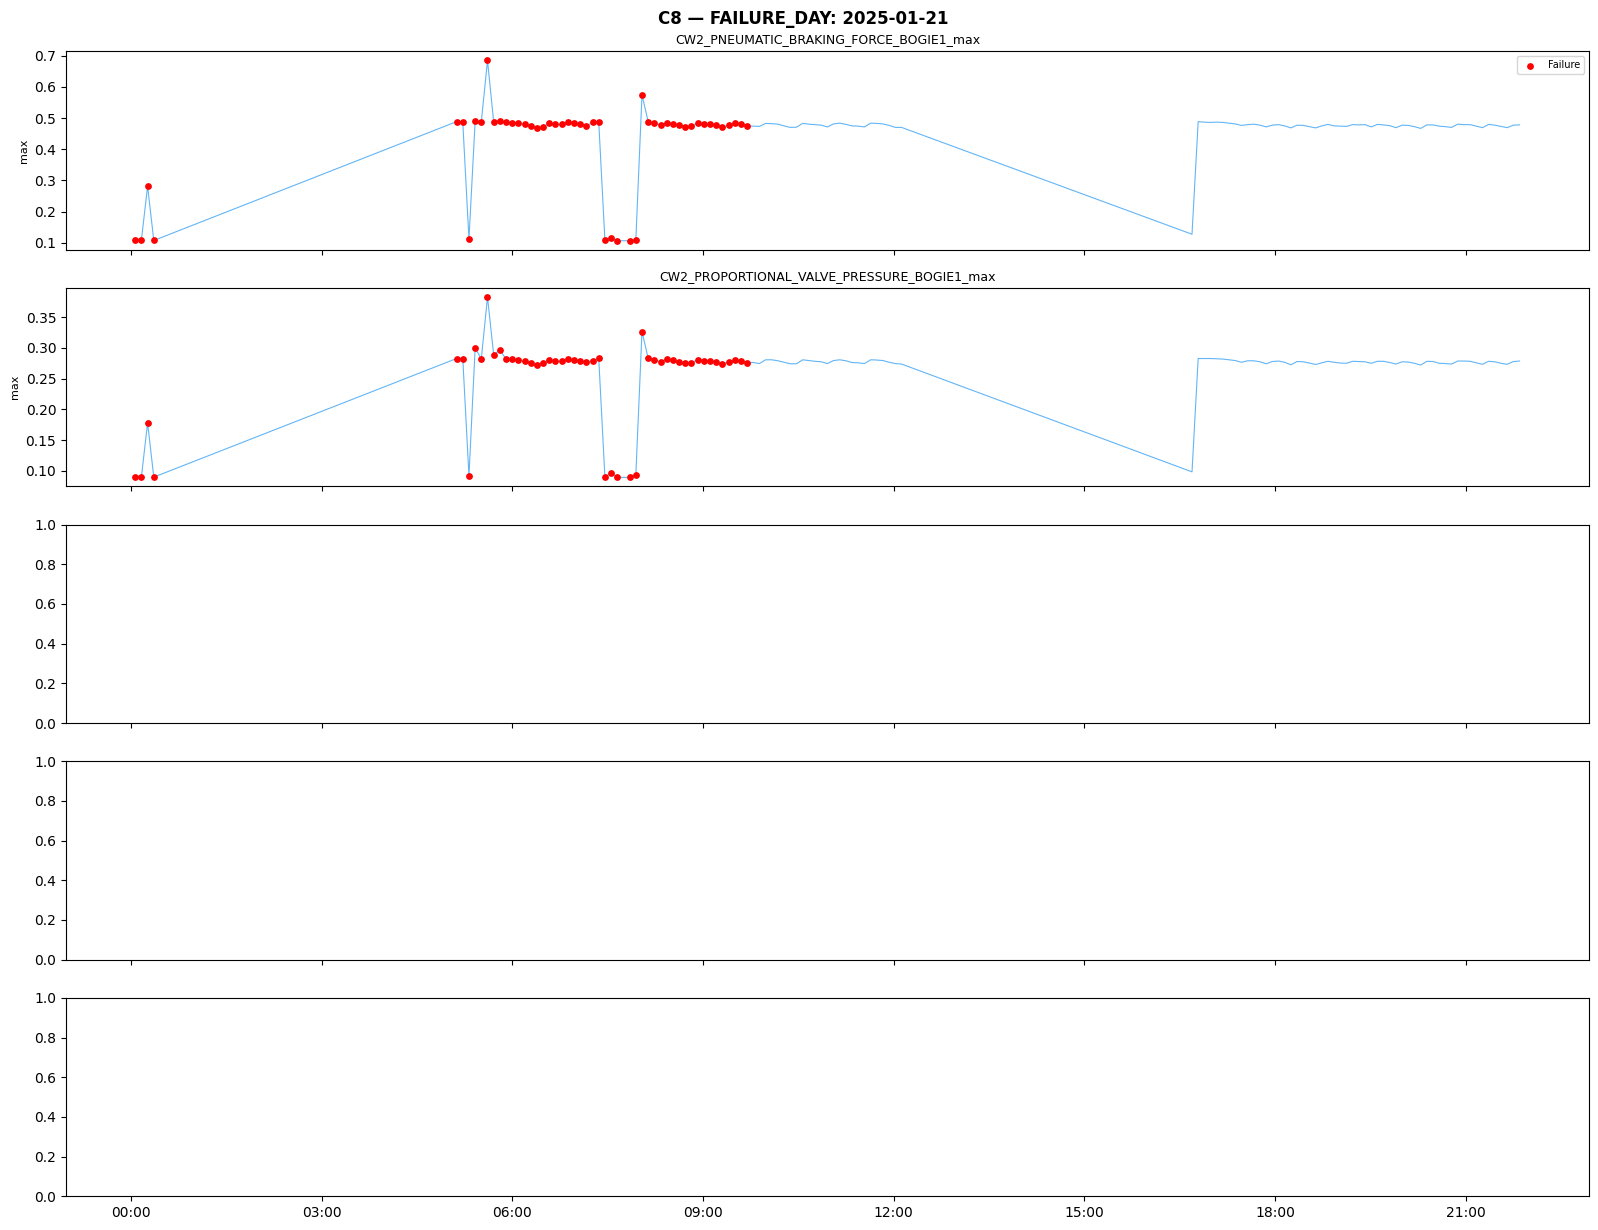

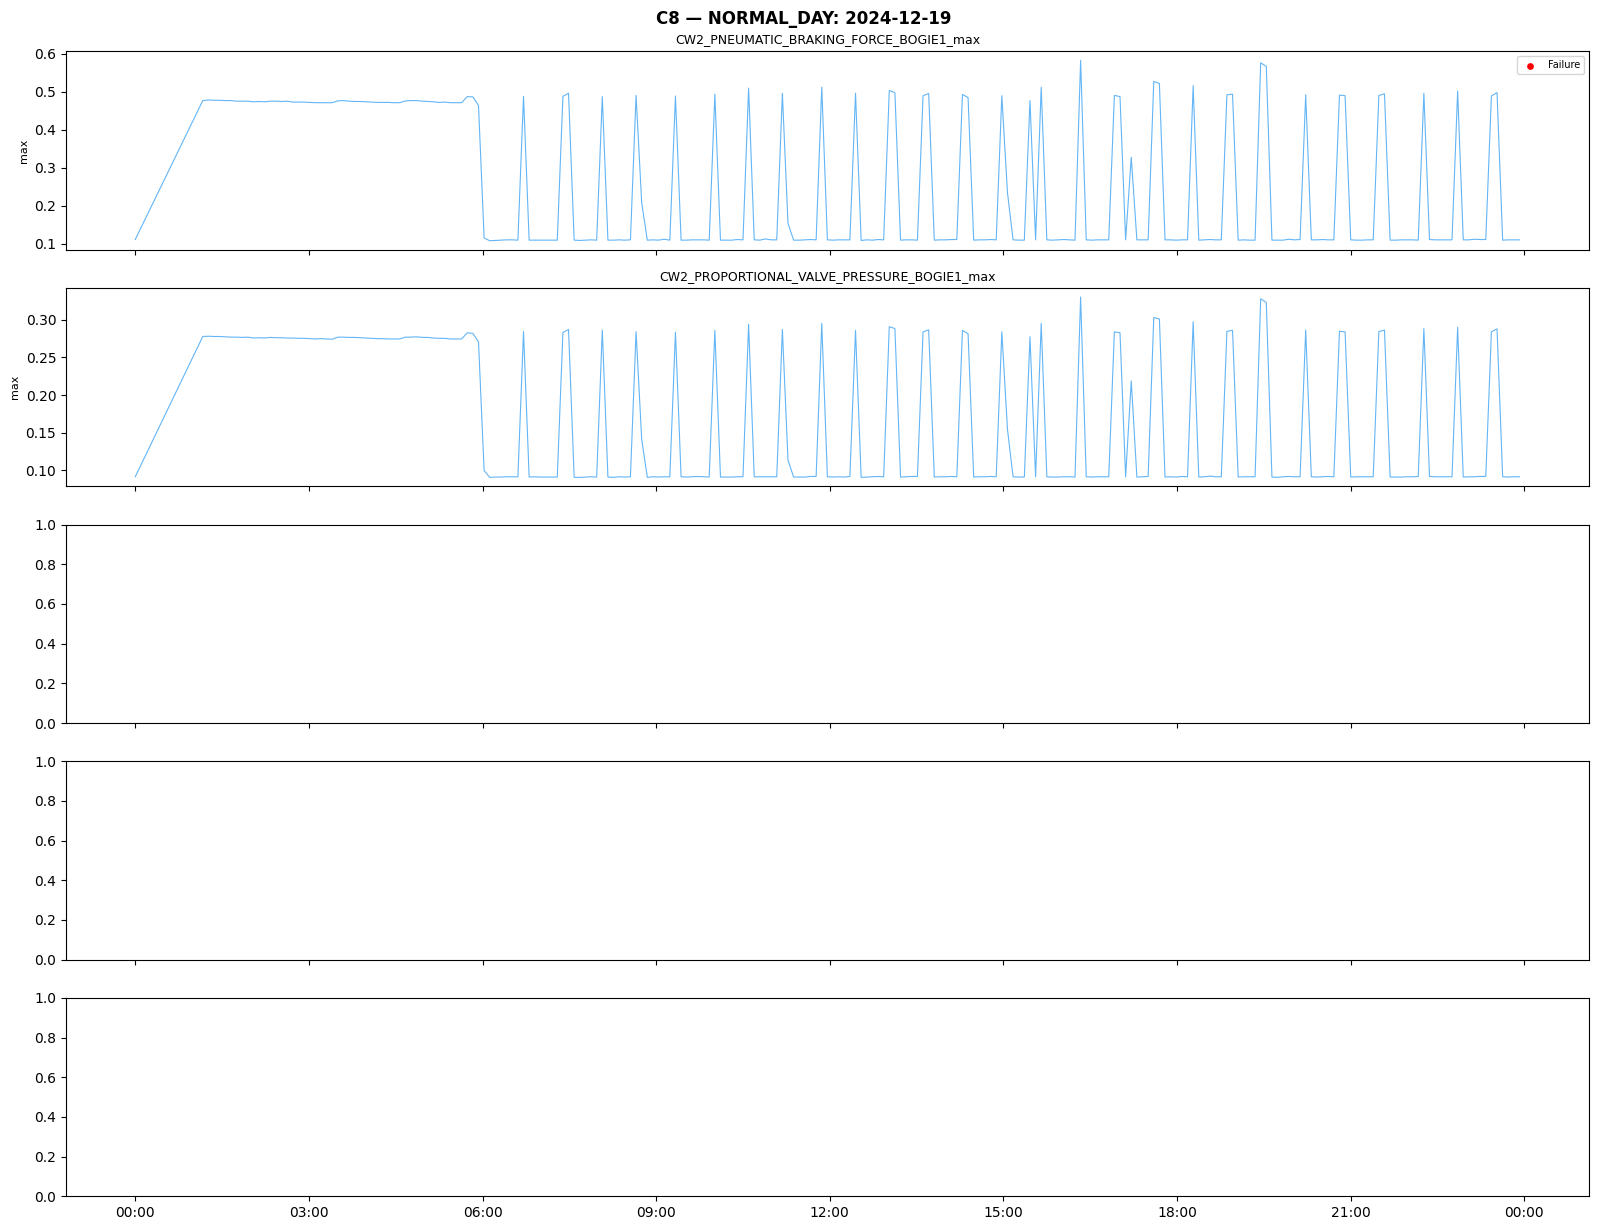

In [9]:
# Same for C8
target_cl2 = 8 if 8 in clusters else sorted(clusters.keys())[1]
if failure_day:
    plot_day(failure_day, 'FAILURE_DAY', target_cl2, clusters[target_cl2])
if normal_day:
    plot_day(normal_day, 'NORMAL_DAY', target_cl2, clusters[target_cl2])

## 10. Two Heuristic Approaches

Try two different clustering strategies and compare. Addresses feedback #4.

**Heuristic A:** Current approach (Jaccard distance, average linkage, t=0.7)
**Heuristic B:** Correlation-based clustering (absolute Pearson correlation as similarity)

In [11]:
# Heuristic A: already computed above (Jaccard + average linkage)
heuristic_a = clusters.copy()
n_clusters_a = len(heuristic_a)

# Heuristic B: Correlation-based clustering on anomalous windows
# Use absolute Pearson correlation as distance: d = 1 - |r|
anom_data = all_data.loc[anomaly_idx, feature_cols]
corr_matrix = anom_data.corr().abs()
corr_dist = 1 - corr_matrix.values
np.fill_diagonal(corr_dist, 0)
corr_dist = np.clip(corr_dist, 0, None)  # ensure non-negative

# Condensed distance matrix
from scipy.spatial.distance import squareform
corr_dist_condensed = squareform(corr_dist)

Z_corr = linkage(corr_dist_condensed, method='average')
cluster_labels_b = fcluster(Z_corr, t=0.5, criterion='distance')

heuristic_b = {}
for feat, cl in zip(feature_cols, cluster_labels_b):
    if cl not in heuristic_b:
        heuristic_b[cl] = []
    heuristic_b[cl].append(feat)

n_clusters_b = len(heuristic_b)

print(f"Heuristic A (Jaccard): {n_clusters_a} clusters")
print(f"Heuristic B (Correlation): {n_clusters_b} clusters")
print()

# Compare: which features move between clusters?
print("Heuristic B clusters (top 10 by size):")
for cl_id in sorted(heuristic_b.keys(), key=lambda x: len(heuristic_b[x]), reverse=True)[:10]:
    feats = heuristic_b[cl_id]
    cl_active = activation_matrix[feats].any(axis=1)
    n_windows = cl_active.sum()
    n_fail = all_data.loc[anomaly_idx[cl_active], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_windows, 1)
    sensors = set()
    for f in feats:
        for suffix in ['_min','_max','_mean','_sum']:
            if f.endswith(suffix):
                sensors.add(f[:-len(suffix)])
                break
    print(f"  C{cl_id}: {len(feats)} features, {len(sensors)} sensors, {n_windows} windows, {fail_pct:.1f}% failure")

Heuristic A (Jaccard): 51 clusters
Heuristic B (Correlation): 23 clusters

Heuristic B clusters (top 10 by size):
  C17: 183 features, 45 sensors, 4961 windows, 10.0% failure
  C15: 48 features, 12 sensors, 7646 windows, 6.5% failure
  C13: 28 features, 28 sensors, 3332 windows, 10.2% failure
  C20: 12 features, 3 sensors, 1900 windows, 13.4% failure
  C22: 12 features, 4 sensors, 3009 windows, 7.7% failure
  C14: 8 features, 2 sensors, 4027 windows, 9.9% failure
  C8: 7 features, 6 sensors, 1403 windows, 8.1% failure
  C9: 6 features, 2 sensors, 528 windows, 14.8% failure
  C11: 4 features, 1 sensors, 1358 windows, 8.5% failure
  C12: 4 features, 1 sensors, 1369 windows, 2.1% failure


Adjusted Rand Index between Heuristic A and B: 0.258
(1.0 = identical clustering, 0.0 = random)
Pairwise co-membership agreement: 0.727


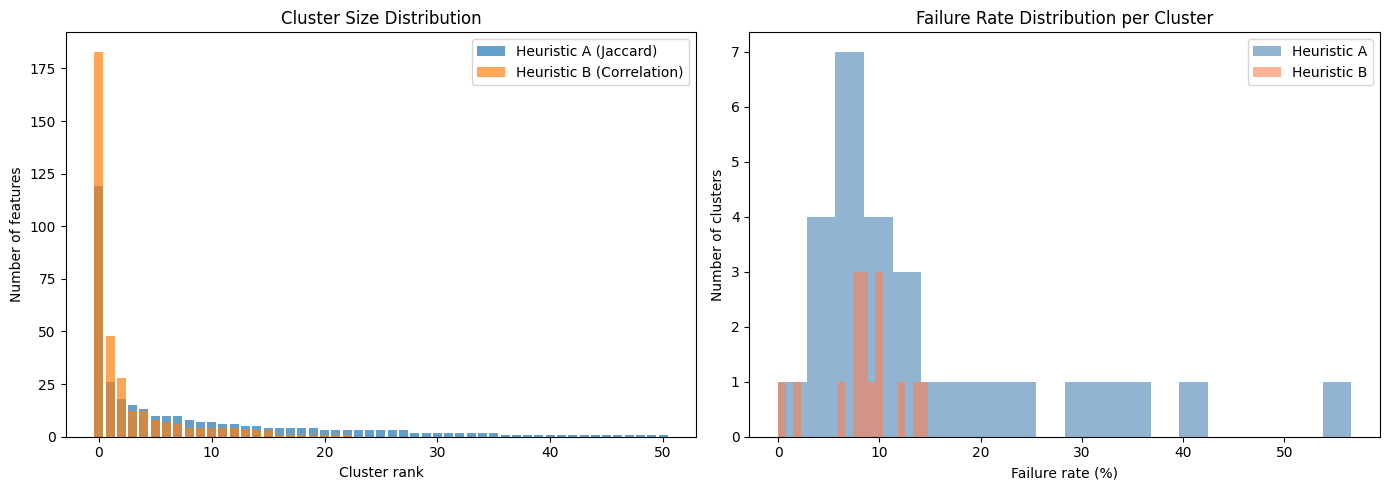

In [12]:
# Side-by-side comparison visualization
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(cluster_labels, cluster_labels_b)
print(f"Adjusted Rand Index between Heuristic A and B: {ari:.3f}")
print("(1.0 = identical clustering, 0.0 = random)")

# Stability check: how many features stay in the same group?
# Build a co-membership matrix for each heuristic
def co_membership(labels):
    n = len(labels)
    co = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i+1, n):
            if labels[i] == labels[j]:
                co[i, j] = 1
                co[j, i] = 1
    return co

co_a = co_membership(cluster_labels)
co_b = co_membership(cluster_labels_b)
agreement = (co_a == co_b).sum() / co_a.size
print(f"Pairwise co-membership agreement: {agreement:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Cluster size distributions
sizes_a = sorted([len(v) for v in heuristic_a.values()], reverse=True)
sizes_b = sorted([len(v) for v in heuristic_b.values()], reverse=True)

axes[0].bar(range(len(sizes_a)), sizes_a, alpha=0.7, label='Heuristic A (Jaccard)')
axes[0].bar(range(len(sizes_b)), sizes_b, alpha=0.7, label='Heuristic B (Correlation)')
axes[0].set_xlabel('Cluster rank')
axes[0].set_ylabel('Number of features')
axes[0].set_title('Cluster Size Distribution')
axes[0].legend()

# Failure rate comparison
fail_rates_a, fail_rates_b = [], []
for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    if len(feats) < 3: continue
    cl_active = activation_matrix[feats].any(axis=1)
    n_w = cl_active.sum()
    n_f = all_data.loc[anomaly_idx[cl_active], 'label'].sum()
    fail_rates_a.append(100 * n_f / max(n_w, 1))

for cl_id in sorted(heuristic_b.keys()):
    feats = heuristic_b[cl_id]
    if len(feats) < 3: continue
    cl_active = activation_matrix[feats].any(axis=1)
    n_w = cl_active.sum()
    n_f = all_data.loc[anomaly_idx[cl_active], 'label'].sum()
    fail_rates_b.append(100 * n_f / max(n_w, 1))

axes[1].hist(fail_rates_a, bins=20, alpha=0.6, label='Heuristic A', color='steelblue')
axes[1].hist(fail_rates_b, bins=20, alpha=0.6, label='Heuristic B', color='coral')
axes[1].set_xlabel('Failure rate (%)')
axes[1].set_ylabel('Number of clusters')
axes[1].set_title('Failure Rate Distribution per Cluster')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'heuristic_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

## 11. Cluster Validation: Keep or Junk?

For each cluster, apply a decision framework:
- **KEEP** if: high failure%, coherent sensors, clear signal shift, matches subsystem
- **JUNK** if: low activation, no failure overlap, noisy/random features, no clear pattern

Addresses feedback #6, #7.

In [13]:
# Validation scorecard for each cluster
validation = []
for cl_id in sorted(clusters.keys()):
    feats = clusters[cl_id]
    if len(feats) < 2:
        continue
    
    cl_active = activation_matrix[feats].any(axis=1)
    active_windows = anomaly_idx[cl_active]
    n_windows = len(active_windows)
    n_fail = all_data.loc[active_windows, 'label'].sum()
    fail_pct = 100 * n_fail / max(n_windows, 1)
    
    # Within-cluster correlation (coherence)
    if len(feats) >= 3:
        sample = all_data.iloc[sample_idx][feats].corr().abs()
        avg_corr = sample.values[np.triu_indices(len(feats), k=1)].mean()
    else:
        avg_corr = all_data.iloc[sample_idx][feats].corr().abs().iloc[0, 1] if len(feats) == 2 else 0
    
    # Mean absolute shift from normal
    shifts = []
    for feat in feats:
        normal_mean = all_data.loc[all_data['label'] == 0, feat].mean()
        anom_mean = all_data.loc[active_windows, feat].mean()
        normal_std = all_data.loc[all_data['label'] == 0, feat].std()
        if normal_std > 0:
            shifts.append(abs(anom_mean - normal_mean) / normal_std)
    avg_shift = np.mean(shifts) if shifts else 0
    
    # Decision
    score = 0
    reasons = []
    if fail_pct >= 5:
        score += 2; reasons.append(f"high fail% ({fail_pct:.0f}%)")
    elif fail_pct >= 2:
        score += 1; reasons.append(f"moderate fail% ({fail_pct:.0f}%)")
    if avg_corr >= 0.5:
        score += 2; reasons.append(f"coherent ({avg_corr:.2f})")
    elif avg_corr >= 0.3:
        score += 1; reasons.append(f"moderate coherence ({avg_corr:.2f})")
    if avg_shift >= 1.0:
        score += 2; reasons.append(f"clear shift ({avg_shift:.1f}σ)")
    elif avg_shift >= 0.5:
        score += 1; reasons.append(f"moderate shift ({avg_shift:.1f}σ)")
    if n_windows >= 100:
        score += 1; reasons.append(f"sufficient data ({n_windows}w)")
    
    decision = "KEEP" if score >= 4 else "REVIEW" if score >= 2 else "JUNK"
    
    validation.append({
        'Cluster': f'C{cl_id}',
        'Features': len(feats),
        'Windows': n_windows,
        'Fail%': f'{fail_pct:.1f}',
        'Coherence': f'{avg_corr:.2f}',
        'Shift': f'{avg_shift:.1f}σ',
        'Score': score,
        'Decision': decision,
        'Reasons': '; '.join(reasons),
    })

val_df = pd.DataFrame(validation)
print("CLUSTER VALIDATION SCORECARD")
print("="*120)
print(val_df.to_string(index=False))
print()
print(f"KEEP: {sum(1 for v in validation if v['Decision']=='KEEP')}")
print(f"REVIEW: {sum(1 for v in validation if v['Decision']=='REVIEW')}")
print(f"JUNK: {sum(1 for v in validation if v['Decision']=='JUNK')}")

CLUSTER VALIDATION SCORECARD
Cluster  Features  Windows Fail% Coherence Shift  Score Decision                                                                                  Reasons
     C1       119        0   0.0      0.69  nanσ      2   REVIEW                                                                          coherent (0.69)
     C2         8       57  22.8      0.91  2.3σ      6     KEEP                                    high fail% (23%); coherent (0.91); clear shift (2.3σ)
     C3         2       34   2.9      0.94  3.5σ      5     KEEP                                 moderate fail% (3%); coherent (0.94); clear shift (3.5σ)
     C4         4       28   3.6      0.94  3.4σ      5     KEEP                                 moderate fail% (4%); coherent (0.94); clear shift (3.4σ)
     C7         3       22  40.9      0.88  2.8σ      6     KEEP                                    high fail% (41%); coherent (0.88); clear shift (2.8σ)
     C8         2        3  66.7      0.97  3.8

## 12. Traceability Summary

Full chain: raw sensor → anomaly detection → cluster → failure mapping. One table per KEEP cluster. Addresses feedback #16, #17.

In [14]:
# Traceability card for each KEEP cluster
keep_clusters = [v for v in validation if v['Decision'] == 'KEEP']

for v in keep_clusters:
    cl_id = int(v['Cluster'][1:])
    feats = clusters[cl_id]
    cl_active = activation_matrix[feats].any(axis=1)
    active_windows = anomaly_idx[cl_active]
    
    # Top 10 features
    act_freq = activation_matrix.loc[active_windows, feats].sum().sort_values(ascending=False)
    top_feats = act_freq.head(10).index.tolist()
    
    # Sensor names (without stat suffix)
    sensors = set()
    for f in feats:
        for suffix in ['_min','_max','_mean','_sum']:
            if f.endswith(suffix):
                sensors.add(f[:-len(suffix)])
                break
    
    # Failure period overlap
    hit_periods = []
    active_set = set(active_windows.tolist())
    for i, fp in enumerate(failure_periods):
        period_indices = set(range(fp['start_idx'], fp['end_idx']+1))
        overlap = len(period_indices & active_set)
        if overlap > 0:
            hit_periods.append(f"FP{i+1} ({fp['start_time'].strftime('%Y-%m-%d')} to {fp['end_time'].strftime('%Y-%m-%d')}, {overlap}/{fp['n_windows']} windows)")
    
    # Window length stats
    window_times = all_data.loc[active_windows, 'window_end']
    
    print(f"\n{'='*100}")
    print(f"TRACEABILITY CARD — Cluster {cl_id}")
    print(f"{'='*100}")
    print(f"Decision: {v['Decision']} (score {v['Score']})")
    print(f"Reasons: {v['Reasons']}")
    print(f"\n--- Sensors ({len(sensors)}) ---")
    for s in sorted(sensors):
        print(f"  {s}")
    print(f"\n--- Top 10 Features (by activation frequency) ---")
    for feat in top_feats:
        normal_mean = all_data.loc[all_data['label']==0, feat].mean()
        anom_mean = all_data.loc[active_windows, feat].mean()
        anom_min = all_data.loc[active_windows, feat].min()
        anom_max = all_data.loc[active_windows, feat].max()
        print(f"  {feat:<50} normal_mean={normal_mean:>8.3f}  anom: mean={anom_mean:>8.3f} min={anom_min:>8.3f} max={anom_max:>8.3f}")
    print(f"\n--- Windows ---")
    print(f"  Total: {len(active_windows)}")
    print(f"  Failure: {all_data.loc[active_windows, 'label'].sum()}")
    print(f"  Time range: {window_times.min()} to {window_times.max()}")
    print(f"\n--- Failure Period Overlap ---")
    for fp_str in hit_periods:
        print(f"  {fp_str}")
    if not hit_periods:
        print("  None")


TRACEABILITY CARD — Cluster 2
Decision: KEEP (score 6)
Reasons: high fail% (23%); coherent (0.91); clear shift (2.3σ)

--- Sensors (0) ---

--- Top 10 Features (by activation frequency) ---
  CW2_PNEUMATIC_BRAKE_ACTIVE_flips                   normal_mean=   7.630  anom: mean=  19.368 min=   0.000 max=  49.000
  CW1_PROPORTIONAL_VALVE_PRESSURE_AVAILABLE_BOGIE2_flips normal_mean=   7.707  anom: mean=  27.228 min=  10.000 max=  66.000
  CW1_PNEUMATIC_BRAKE_ACTIVE_flips                   normal_mean=   7.852  anom: mean=  18.684 min=   0.000 max=  45.000
  CW2_PROPORTIONAL_VALVE_PRESSURE_AVAILABLE_BOGIE2_flips normal_mean=   7.148  anom: mean=  18.123 min=   0.000 max=  57.000
  CW2_PROPORTIONAL_VALVE_PRESSURE_AVAILABLE_BOGIE1_flips normal_mean=   6.970  anom: mean=  17.070 min=   0.000 max=  57.000
  CW1_PROPORTIONAL_VALVE_PRESSURE_AVAILABLE_BOGIE1_flips normal_mean=   7.408  anom: mean=  17.439 min=   0.000 max=  45.000
  MW3_PROPORTIONAL_VALVE_PRESSURE_AVAILABLE_BOGIE1_flips normal_mea

  MW2_SPRING_BRAKE_PRESSURE_BOGIE2_mean              normal_mean=   0.669  anom: mean=   0.340 min=   0.000 max=   0.797
  CW1_SPRING_BRAKE_PRESSURE_BOGIE2_mean              normal_mean=   0.670  anom: mean=   0.346 min=   0.000 max=   0.780
  CW2_SPRING_BRAKE_PRESSURE_BOGIE2_mean              normal_mean=   0.670  anom: mean=   0.356 min=   0.000 max=   0.798
  MW4_SPRING_BRAKE_PRESSURE_BOGIE1_max               normal_mean=   0.696  anom: mean=   0.388 min=   0.000 max=   0.799

--- Windows ---
  Total: 1128
  Failure: 250
  Time range: 2024-06-04 04:20:50 to 2025-06-28 06:20:50

--- Failure Period Overlap ---
  FP1 (2024-06-27 to 2024-06-27, 36/74 windows)
  FP2 (2024-08-19 to 2024-08-19, 26/27 windows)
  FP3 (2024-09-03 to 2024-09-03, 6/43 windows)
  FP4 (2024-09-21 to 2024-09-22, 10/65 windows)
  FP5 (2024-10-05 to 2024-10-08, 37/177 windows)
  FP6 (2024-10-10 to 2024-10-10, 10/28 windows)
  FP7 (2024-12-14 to 2024-12-14, 22/68 windows)
  FP8 (2025-01-21 to 2025-01-21, 14/51 window

  MW1_LOAD_PRESSURE_BOGIE2_min                       normal_mean=   0.201  anom: mean=   0.250 min=   0.000 max=   0.440
  MW1_LOAD_PRESSURE_BOGIE1_min                       normal_mean=   0.196  anom: mean=   0.174 min=   0.000 max=   0.370
  MW1_LOAD_PRESSURE_BOGIE1_mean                      normal_mean=   0.230  anom: mean=   0.203 min=   0.000 max=   0.389
  MW1_LOAD_PRESSURE_BOGIE1_max                       normal_mean=   0.283  anom: mean=   0.231 min=   0.000 max=   0.429

--- Windows ---
  Total: 2252
  Failure: 201
  Time range: 2024-06-01 17:20:00 to 2025-06-30 09:46:40

--- Failure Period Overlap ---
  FP1 (2024-06-27 to 2024-06-27, 35/74 windows)
  FP5 (2024-10-05 to 2024-10-08, 26/177 windows)
  FP6 (2024-10-10 to 2024-10-10, 3/28 windows)
  FP7 (2024-12-14 to 2024-12-14, 2/68 windows)
  FP9 (2025-02-19 to 2025-02-19, 1/1 windows)
  FP10 (2025-02-24 to 2025-02-24, 3/79 windows)
  FP11 (2025-02-26 to 2025-02-26, 2/72 windows)
  FP12 (2025-03-14 to 2025-03-14, 1/55 windows)


  MW4_PROPORTIONAL_VALVE_PRESSURE_BOGIE2_max         normal_mean=   0.440  anom: mean=   0.207 min=   0.000 max=   0.558
  CW1_PNEUMATIC_BRAKING_FORCE_BOGIE2_max             normal_mean=   0.395  anom: mean=   0.210 min=   0.000 max=   0.534
  CW2_PROPORTIONAL_VALVE_PRESSURE_BOGIE2_max         normal_mean=   0.428  anom: mean=   0.242 min=   0.000 max=   0.561
  TRAIN_SPEED_ACTUAL_min                             normal_mean=   0.000  anom: mean=   0.067 min=   0.000 max=   1.000

--- Windows ---
  Total: 299
  Failure: 54
  Time range: 2024-06-02 00:43:20 to 2025-06-30 04:37:30

--- Failure Period Overlap ---
  FP2 (2024-08-19 to 2024-08-19, 1/27 windows)
  FP5 (2024-10-05 to 2024-10-08, 23/177 windows)
  FP6 (2024-10-10 to 2024-10-10, 1/28 windows)
  FP7 (2024-12-14 to 2024-12-14, 10/68 windows)
  FP11 (2025-02-26 to 2025-02-26, 1/72 windows)
  FP12 (2025-03-14 to 2025-03-14, 7/55 windows)
  FP13 (2025-04-10 to 2025-04-10, 1/81 windows)
  FP15 (2025-05-05 to 2025-05-05, 3/78 windows)



TRACEABILITY CARD — Cluster 44
Decision: KEEP (score 7)
Reasons: high fail% (34%); coherent (0.58); clear shift (3.5σ); sufficient data (278w)

--- Sensors (10) ---
  CW2_SPRING_BRAKE_PRESSURE_BOGIE2
  MW1_ENERGY_BRAKING_RESISTANCE
  MW1_SPRING_BRAKE_PRESSURE_BOGIE1
  MW2_ENERGY_BRAKING_RESISTANCE
  MW2_SPRING_BRAKE_PRESSURE_BOGIE1
  MW2_SPRING_BRAKE_PRESSURE_BOGIE2
  MW3_ENERGY_BRAKING_RESISTANCE
  MW3_SPRING_BRAKE_PRESSURE_BOGIE1
  MW4_SPRING_BRAKE_PRESSURE_BOGIE1
  MW4_SPRING_BRAKE_PRESSURE_BOGIE2

--- Top 10 Features (by activation frequency) ---
  MW4_SPRING_BRAKE_PRESSURE_BOGIE1_min               normal_mean=   0.595  anom: mean=   0.135 min=   0.000 max=   0.778
  MW4_SPRING_BRAKE_PRESSURE_BOGIE2_min               normal_mean=   0.594  anom: mean=   0.143 min=   0.000 max=   0.784
  MW2_SPRING_BRAKE_PRESSURE_BOGIE1_min               normal_mean=   0.605  anom: mean=   0.178 min=   0.000 max=   0.794
  MW3_SPRING_BRAKE_PRESSURE_BOGIE1_min               normal_mean=   0.598  anom

## 13. Improved Visualization: Cluster Overview Heatmap

Better heatmap showing clusters vs sensors with failure rates and coherence. No premature naming — use pattern IDs only. Addresses feedback #2, #8.

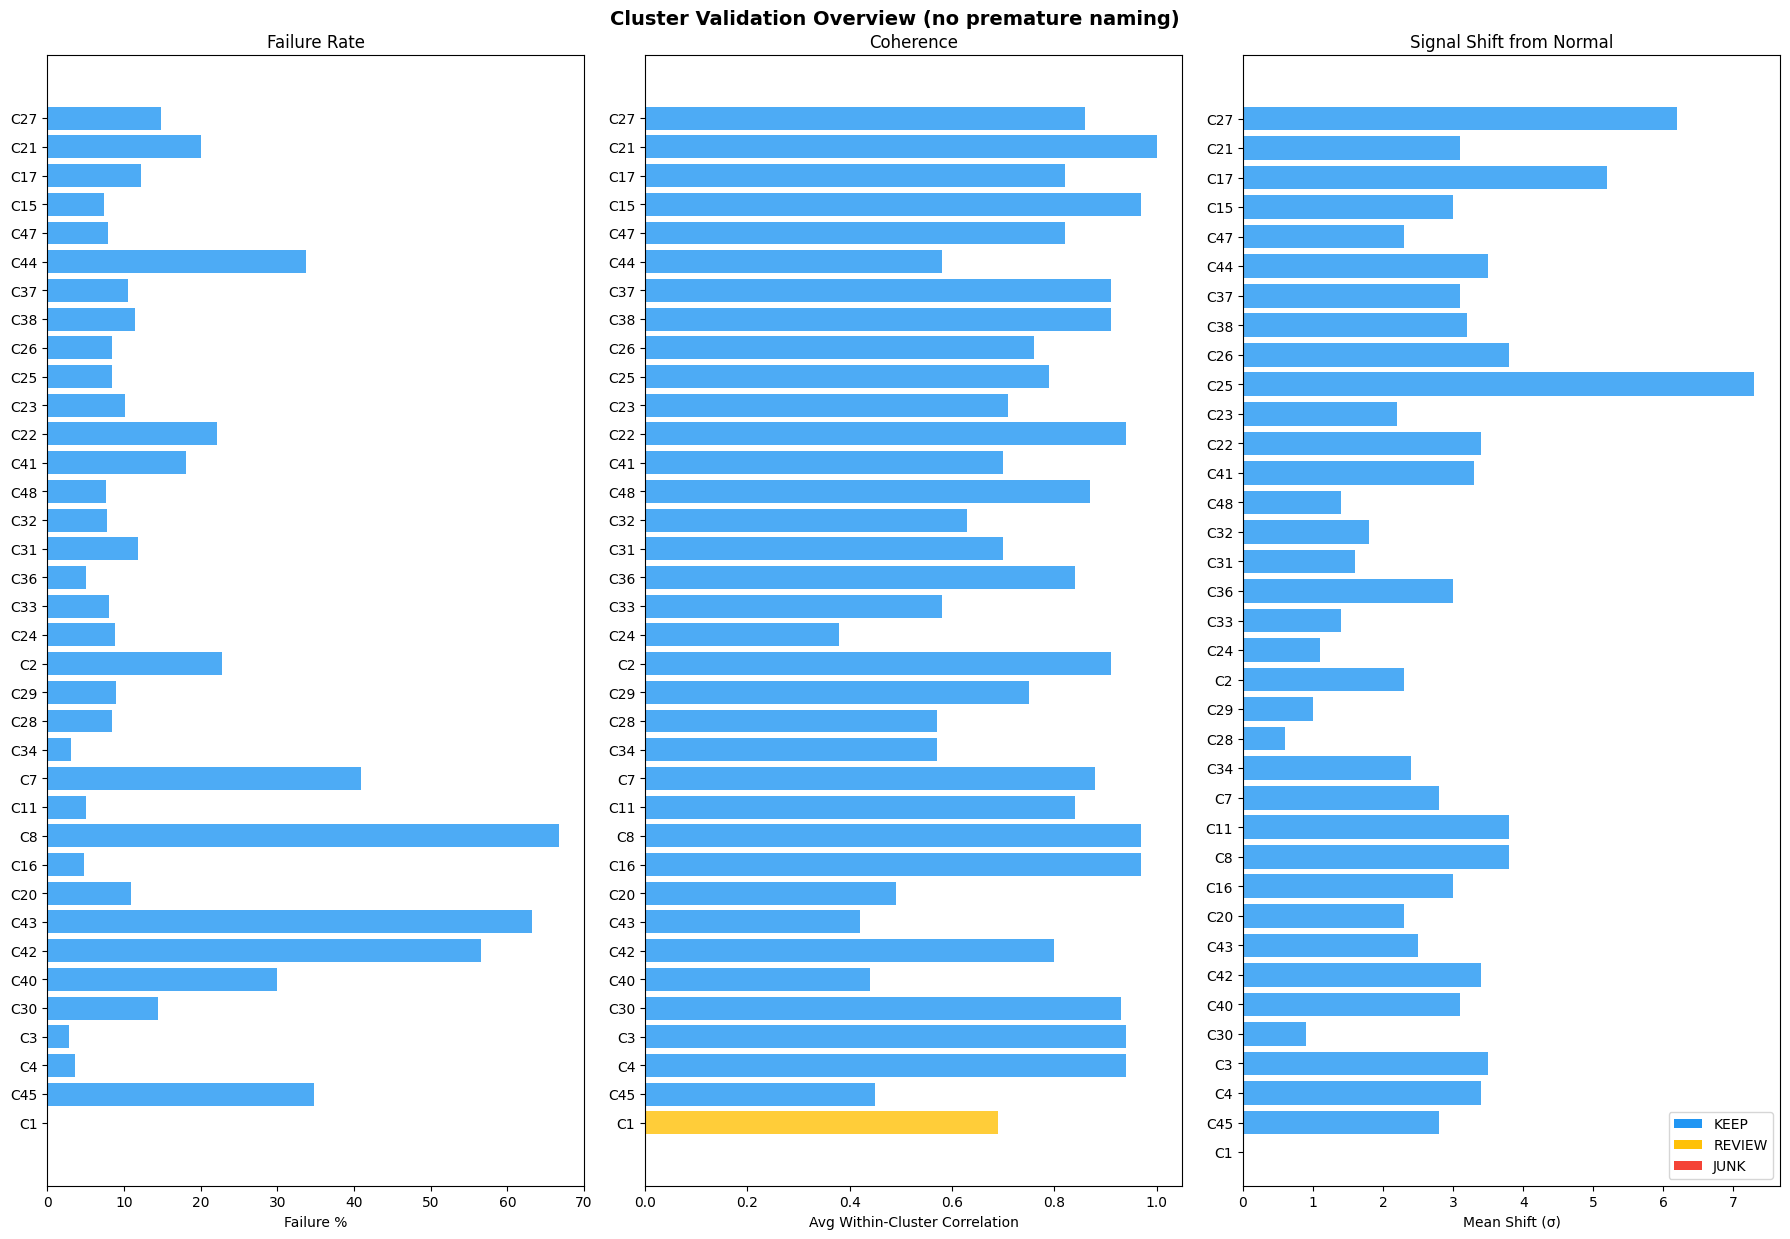


KEEP clusters for expert review:
  C27: 2 sensors, 528 windows, 14.8% failure, coherence=0.86
  C21: 2 sensors, 303 windows, 20.1% failure, coherence=1.00
  C17: 0 sensors, 532 windows, 12.2% failure, coherence=0.82
  C15: 5 sensors, 458 windows, 7.4% failure, coherence=0.97
  C47: 10 sensors, 4856 windows, 7.9% failure, coherence=0.82
  C44: 10 sensors, 278 windows, 33.8% failure, coherence=0.58
  C37: 4 sensors, 1090 windows, 10.5% failure, coherence=0.91
  C38: 3 sensors, 709 windows, 11.4% failure, coherence=0.91
  C26: 1 sensors, 1358 windows, 8.5% failure, coherence=0.76
  C25: 1 sensors, 652 windows, 8.4% failure, coherence=0.79
  C23: 26 sensors, 3332 windows, 10.2% failure, coherence=0.71
  C22: 9 sensors, 1128 windows, 22.2% failure, coherence=0.94
  C41: 7 sensors, 299 windows, 18.1% failure, coherence=0.70
  C48: 2 sensors, 3008 windows, 7.7% failure, coherence=0.87
  C32: 1 sensors, 526 windows, 7.8% failure, coherence=0.63
  C31: 3 sensors, 832 windows, 11.9% failure, co

In [15]:
# Build overview: clusters (rows) vs key metrics
overview_rows = []
for v in validation:
    cl_id = int(v['Cluster'][1:])
    feats = clusters[cl_id]
    sensors = set()
    for f in feats:
        for suffix in ['_min','_max','_mean','_sum']:
            if f.endswith(suffix):
                sensors.add(f[:-len(suffix)])
                break
    overview_rows.append({
        'Pattern': v['Cluster'],
        'N_Sensors': len(sensors),
        'N_Features': len(feats),
        'Windows': v['Windows'],
        'Fail%': float(v['Fail%']),
        'Coherence': float(v['Coherence']),
        'Shift_Sigma': float(v['Shift'].replace('σ','')),
        'Score': v['Score'],
        'Decision': v['Decision'],
    })

ov_df = pd.DataFrame(overview_rows).sort_values('Score', ascending=False)

# Color-coded visualization
fig, axes = plt.subplots(1, 3, figsize=(18, max(6, len(ov_df)*0.35)))

# Failure rate
colors = ov_df['Decision'].map({'KEEP': '#2196F3', 'REVIEW': '#FFC107', 'JUNK': '#F44336'})
axes[0].barh(ov_df['Pattern'], ov_df['Fail%'], color=colors, alpha=0.8)
axes[0].set_xlabel('Failure %')
axes[0].set_title('Failure Rate')
axes[0].invert_yaxis()

# Coherence
axes[1].barh(ov_df['Pattern'], ov_df['Coherence'], color=colors, alpha=0.8)
axes[1].set_xlabel('Avg Within-Cluster Correlation')
axes[1].set_title('Coherence')
axes[1].invert_yaxis()

# Signal Shift
axes[2].barh(ov_df['Pattern'], ov_df['Shift_Sigma'], color=colors, alpha=0.8)
axes[2].set_xlabel('Mean Shift (σ)')
axes[2].set_title('Signal Shift from Normal')
axes[2].invert_yaxis()

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2196F3', label='KEEP'),
                   Patch(facecolor='#FFC107', label='REVIEW'),
                   Patch(facecolor='#F44336', label='JUNK')]
axes[2].legend(handles=legend_elements, loc='lower right')

plt.suptitle('Cluster Validation Overview (no premature naming)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'cluster_validation_overview.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nKEEP clusters for expert review:")
for _, row in ov_df[ov_df['Decision']=='KEEP'].iterrows():
    print(f"  {row['Pattern']}: {row['N_Sensors']} sensors, {row['Windows']} windows, {row['Fail%']:.1f}% failure, coherence={row['Coherence']:.2f}")

## Traceability: Pipeline Position

**NB01 > NB02 > NB03 > NB04 > NB05**

### What this notebook provides:
- Cluster-to-failure event matching
- Subsystem activation breakdown per cluster
- Subsystem-aware feature group construction
- Consolidated patterns (P1-P6)
- Two heuristic comparison (Jaccard vs correlation-based)
- Keep/junk validation scorecard
- 2-day raw sensor unfold
- Traceability cards per cluster

### Depends on:
- NB04 cluster assignments (reproduced in setup cell)
- outputs/supervised/train.parquet and test.parquet